<a href="https://colab.research.google.com/github/faisalsuryasaputra/nst-vgg19-GenerativeAI-kelompok13/blob/main/nst_kelompok13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Neural Style Transfer (NST) dari Nol — Kelompok 13**

**Mata Kuliah:** Generative AI  |  **Proyek:** Vibe Coding Generative AI From Scratch

| Anggota | Peran | Tanggung jawab di notebook |
|---|---|---|
| Yudis Akbar | Prompt Engineer & LLM Navigator | Arsitektur NST, konsistensi kode antar bagian |
| Faisal Surya Saputra | Data Pipeline & Preprocessing Engineer | Bagian 2 dan 2.5 (dataset, augmentasi, DataLoader, shape input) |
| Faza Farih Riyadi | Training Loop & Hyperparameter Tuning Engineer | Bagian 4-8 (loss, optimasi, eksperimen) |
| Danang Setiyoadi | Lead Documentarian & Error Handler | Log interaksi LLM, penanganan error, laporan |

**Model:** Neural Style Transfer berbasis optimasi piksel dengan VGG-19 pralatih (ImageNet). Content Loss pada `conv4_2`, Style Loss berbasis Gram Matrix pada `conv1_1`–`conv5_1`.

**Alasan memilih NST:** ringan di GPU Colab dan hasilnya mudah dinilai secara visual.

**Catatan from scratch:** bobot VGG-19 pralatih dipakai hanya sebagai pengekstrak fitur bagian dari metode NST. Fungsi loss, Gram Matrix, pipeline data, dan loop optimasi ditulis sendiri lewat vibe coding.

## **Bagian 1: Setup & Konfigurasi**

---



In [2]:
# ============================================================
# BAGIAN 1: SETUP_CONFIG
# ============================================================
import os
import random
from dataclasses import dataclass, field, asdict, replace
from typing import List

import numpy as np
import torch

Sel ini mengimpor pustaka dasar: os, random, numpy, torch, dan dataclass untuk membuat kelas konfigurasi.

### **1.1 Definisi Kelas Config**

In [3]:
@dataclass
class Config:
    """Satu-satunya tempat semua hyperparameter dan pengaturan proyek NST."""

    # --- Reproduksibilitas ---
    seed: int = 42

    # --- Gambar ---
    image_size: int = 256                        # sisi gambar (H = W)
    content_path: str = "images/content.png"
    style_path: str = "images/style.png"
    output_dir: str = "outputs"

    # --- Layer (nama string; pemetaan ke indeks torchvision ada di Bagian 3) ---
    content_layers: List[str] = field(default_factory=lambda: ["conv4_2"])
    style_layers: List[str] = field(
        default_factory=lambda: ["conv1_1", "conv2_1", "conv3_1", "conv4_1", "conv5_1"]
    )
    # Bobot tiap style layer, urutan SAMA dengan style_layers (rata = 1/5)
    style_layer_weights: List[float] = field(default_factory=lambda: [0.2] * 5)

    # --- Bobot loss (titik awal, BUKAN nilai final) ---
    content_weight: float = 1.0                  # alpha
    style_weight: float = 1e5                    # beta
    tv_weight: float = 0.0                       # 0.0 = Total Variation Loss nonaktif

    # --- Optimasi ---
    optimizer_name: str = "adam"                 # eksperimen lain nanti: "lbfgs"
    lr: float = 0.01
    num_steps: int = 300
    init_mode: str = "content"                   # generated_img = salinan content_img

    # --- Arsitektur ---
    pooling: str = "max"                         # MaxPool bawaan VGG-19 (eksperimen: "avg")

    # --- Logging ---
    log_every: int = 50                          # cetak loss tiap N iterasi

    def __post_init__(self):
        """Validasi dini agar kesalahan konfigurasi tidak muncul diam-diam."""
        if self.image_size <= 0:
            raise ValueError("image_size harus > 0")
        if len(self.style_layers) != len(self.style_layer_weights):
            raise ValueError(
                f"Jumlah style_layers ({len(self.style_layers)}) harus sama dengan "
                f"jumlah style_layer_weights ({len(self.style_layer_weights)})"
            )
        if self.init_mode not in ("content", "noise"):
            raise ValueError("init_mode harus 'content' atau 'noise'")
        if self.optimizer_name not in ("adam", "lbfgs"):
            raise ValueError("optimizer_name harus 'adam' atau 'lbfgs'")
        if self.pooling not in ("max", "avg"):
            raise ValueError("pooling harus 'max' atau 'avg'")
        if self.num_steps <= 0 or self.lr <= 0:
            raise ValueError("num_steps dan lr harus > 0")
        if min(self.content_weight, self.style_weight, self.tv_weight) < 0:
            raise ValueError("Bobot loss tidak boleh negatif")

Semua hyperparameter ditaruh di satu kelas Config supaya mudah diubah dan dilacak. Isinya: layer content conv4_2, lima layer style conv1_1 sampai conv5_1 dengan bobot rata (0.2), style_weight = 1e5, TV loss nonaktif (tv_weight = 0), optimizer Adam dengan lr = 0.01 selama 300 langkah, inisialisasi dari gambar content, dan MaxPool. Konfigurasi yang salah ditolak lewat validasi.

### **1.2 Fungsi Pembantu (set_seed & get_device)**

In [4]:
def set_seed(seed: int) -> None:
    """Mengunci sumber keacakan agar hasil bisa diulang."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def get_device() -> torch.device:
    """Mengembalikan 'cuda' jika GPU tersedia, jika tidak 'cpu'. Dipanggil SEKALI."""
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")

set_seed mengunci angka acak (Python, NumPy, PyTorch) supaya hasil bisa diulang. get_device memilih GPU kalau ada, kalau tidak CPU.

### **1.3 Inisialisasi Project Config & Folder Output**

In [5]:
cfg = Config()
set_seed(cfg.seed)
device = get_device()

os.makedirs(cfg.output_dir, exist_ok=True)
os.makedirs(os.path.dirname(cfg.content_path), exist_ok=True)

print("=" * 65)
print(" SYSTEM & CONFIGURATION SETUP ".center(65, "="))
print("=" * 65)
print(f"  Device                  : {device}")
if device.type == "cuda":
    print(f"  GPU Model               : {torch.cuda.get_device_name(0)}")
print(f"  PyTorch Version         : {torch.__version__}")
print("-" * 65)
print(" PROJECT CONFIGURATION PARAMETERS ".center(65, "-"))
print("-" * 65)
for k, v in asdict(cfg).items():
    print(f"  {k:24s} : {v}")
print("=" * 65)

================== SYSTEM & CONFIGURATION SETUP =================
  Device                  : cuda
  GPU Model               : Tesla T4
  PyTorch Version         : 2.11.0+cu130
-----------------------------------------------------------------
---------------- PROJECT CONFIGURATION PARAMETERS ---------------
-----------------------------------------------------------------
  seed                     : 42
  image_size               : 256
  content_path             : images/content.png
  style_path               : images/style.png
  output_dir               : outputs
  content_layers           : ['conv4_2']
  style_layers             : ['conv1_1', 'conv2_1', 'conv3_1', 'conv4_1', 'conv5_1']
  style_layer_weights      : [0.2, 0.2, 0.2, 0.2, 0.2]
  content_weight           : 1.0
  style_weight             : 100000.0
  tv_weight                : 0.0
  optimizer_name           : adam
  lr                       : 0.01
  num_steps                : 300
  init_mode                : content
  pool

Membuat objek konfigurasi, mengunci seed, memilih device, membuat folder output, lalu mencetak ringkasan sistem dan seluruh parameter.

### **1.4 Unit Pengujian Bagian 1 (Setup Config)**

In [6]:
# ============================================================
# UJI BAGIAN 1
# ============================================================
print("=" * 50)
print("UJI BAGIAN 1: SETUP_CONFIG")
print("=" * 50)

# Uji 1: device terdeteksi
print(f"[Uji 1] device = {device}  ->", "OK (GPU)" if device.type == "cuda" else "PERINGATAN: CPU (akan lambat)")

# Uji 2: nilai Config sesuai keputusan yang disepakati
assert cfg.content_layers == ["conv4_2"]
assert cfg.style_layers == ["conv1_1", "conv2_1", "conv3_1", "conv4_1", "conv5_1"]
assert abs(sum(cfg.style_layer_weights) - 1.0) < 1e-9
assert cfg.content_weight == 1.0 and cfg.style_weight == 1e5
assert cfg.lr == 0.01 and cfg.num_steps == 300
assert cfg.image_size == 256 and cfg.tv_weight == 0.0
assert cfg.init_mode == "content" and cfg.optimizer_name == "adam" and cfg.pooling == "max"
print("[Uji 2] Nilai Config sesuai keputusan: OK")

# Uji 3: set_seed -> hasil acak identik jika seed sama
def sample_randoms():
    return random.random(), float(np.random.rand()), torch.rand(3)

set_seed(cfg.seed); a = sample_randoms()
set_seed(cfg.seed); b = sample_randoms()
assert a[0] == b[0] and a[1] == b[1] and torch.equal(a[2], b[2])
print("[Uji 3] set_seed mereproduksi angka acak yang sama: OK")

# Uji 4: seed berbeda -> hasil berbeda (memastikan seed benar-benar bekerja)
set_seed(cfg.seed + 1); c = sample_randoms()
assert not torch.equal(a[2], c[2])
print("[Uji 4] Seed berbeda menghasilkan angka berbeda: OK")
set_seed(cfg.seed)  # kembalikan ke seed proyek

# Uji 5: tensor bisa dibuat di device
t = torch.zeros(1, 3, cfg.image_size, cfg.image_size, device=device)
assert t.device.type == device.type and t.shape == (1, 3, 256, 256)
print(f"[Uji 5] Tensor uji (1,3,256,256) di {t.device}: OK")

# Uji 6: validasi Config menolak konfigurasi salah
for nama, kwargs in [
    ("bobot layer tidak cocok", dict(style_layer_weights=[0.5, 0.5])),
    ("init_mode salah",         dict(init_mode="foo")),
    ("image_size negatif",      dict(image_size=-1)),
]:
    try:
        Config(**kwargs)
        raise AssertionError(f"Seharusnya error: {nama}")
    except ValueError:
        print(f"[Uji 6] Config menolak '{nama}': OK")

# Uji 7: replace() tidak mengubah cfg asli
cfg_exp = replace(cfg, style_weight=1e6)
assert cfg.style_weight == 1e5 and cfg_exp.style_weight == 1e6
print("[Uji 7] replace() membuat salinan, cfg asli tetap utuh: OK")

print("\nSEMUA UJI BAGIAN 1 LULUS")

UJI BAGIAN 1: SETUP_CONFIG
[Uji 1] device = cuda  -> OK (GPU)
[Uji 2] Nilai Config sesuai keputusan: OK
[Uji 3] set_seed mereproduksi angka acak yang sama: OK
[Uji 4] Seed berbeda menghasilkan angka berbeda: OK
[Uji 5] Tensor uji (1,3,256,256) di cuda:0: OK
[Uji 6] Config menolak 'bobot layer tidak cocok': OK
[Uji 6] Config menolak 'init_mode salah': OK
[Uji 6] Config menolak 'image_size negatif': OK
[Uji 7] replace() membuat salinan, cfg asli tetap utuh: OK

SEMUA UJI BAGIAN 1 LULUS


Unit test Bagian 1: memeriksa device, nilai default Config, seed yang reproducible, dan validasi konfigurasi yang salah.

## **Bagian 2: Pengolahan & Input/Output Gambar**

### **2.1 Memuat Gambar Langsung dari URL Internet**

In [7]:
import requests
from io import BytesIO
from PIL import Image

# Menggunakan URL baru
CONTENT_URL = "https://bioneers.org/wp-content/uploads/2020/04/shutterstock_747646759.jpg"
STYLE_URL   = "https://i.pinimg.com/736x/89/bf/f4/89bff400f362f0142027fb0752cb7166.jpg"

def load_image_from_url(url: str, image_size: int) -> Image.Image:
    """Mengunduh gambar dari internet lewat URL dan mengubahnya ke objek PIL Image."""
    headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"}
    try:
        response = requests.get(url, headers=headers, timeout=15)
        response.raise_for_status()
    except Exception as e:
        raise RuntimeError(f"Gagal mengunduh gambar dari URL: {url}. Error: {e}")

    img = Image.open(BytesIO(response.content)).convert("RGB")
    img = img.resize((image_size, image_size), Image.Resampling.BICUBIC)
    return img

try:
    content_pil = load_image_from_url(CONTENT_URL, cfg.image_size)
    style_pil   = load_image_from_url(STYLE_URL, cfg.image_size)
    print("Gambar konten dan gaya berhasil diunduh secara online!")
except Exception as e:
    print("Gagal memuat dari URL, pastikan link Anda valid dan aktif:", e)

Gambar konten dan gaya berhasil diunduh secara online!


Mengunduh gambar content dan style awal dari URL, mengubahnya ke RGB, lalu memaksa ukurannya menjadi persegi 256×256 dengan resize langsung (rasio aspek tidak dijaga).

In [8]:
# ============================================================
# BAGIAN 2: IMAGE_IO
# (os, numpy, torch sudah diimpor di Bagian 1; tidak diimpor ulang)
# ============================================================
from PIL import Image
import matplotlib.pyplot as plt

Impor PIL dan matplotlib untuk membaca dan menampilkan gambar.

### **2.2 Definisi Fungsi Load, Preprocess, & Denormalisasi Gambar**

In [9]:
def load_image(path: str, image_size: int) -> Image.Image:
    """Membaca file gambar, mengubah ke RGB, lalu resize ke (image_size x image_size).
    Output: objek PIL (belum tensor)."""
    if not os.path.isfile(path):
        raise FileNotFoundError(
            f"File tidak ditemukan: '{path}'. Periksa nama file dan folder di panel Files Colab."
        )
    img = Image.open(path).convert("RGB")          # pastikan 3 kanal (buang alpha/grayscale)
    img = img.resize((image_size, image_size), Image.Resampling.BICUBIC)
    return img


def preprocess(pil_img: Image.Image, device: torch.device) -> torch.Tensor:
    """PIL RGB -> tensor float32 (1, 3, H, W) di rentang [0, 1], dipindah ke device.
    TIDAK ada normalisasi ImageNet di sini (dilakukan di VGGFeatureExtractor, Bagian 3)."""
    arr = np.array(pil_img, dtype=np.float32)       # (H, W, 3), nilai 0..255 (np.array = salinan, aman)
    assert arr.ndim == 3 and arr.shape[2] == 3, f"Diharapkan (H,W,3), dapat {arr.shape}"
    arr = arr / 255.0                               # skala ke [0, 1]
    tensor = torch.from_numpy(arr).permute(2, 0, 1) # (H,W,3) -> (3,H,W)
    tensor = tensor.unsqueeze(0).contiguous()       # (3,H,W) -> (1,3,H,W)
    return tensor.to(device=device, dtype=torch.float32)


def denormalize(img: torch.Tensor) -> torch.Tensor:
    """Menyiapkan tensor untuk ditampilkan/disimpan: lepas dari graf gradien lalu clamp ke [0, 1].
    Tidak mengubah tensor asli dan tidak memindahkan device."""
    assert img.ndim == 4, f"Diharapkan tensor 4 dimensi (1,3,H,W), dapat ndim={img.ndim}"
    return img.detach().clamp(0.0, 1.0)


def tensor_to_pil(img: torch.Tensor) -> Image.Image:
    """Tensor (1, 3, H, W) di [0, 1] -> gambar PIL RGB uint8."""
    assert img.ndim == 4 and img.shape[0] == 1 and img.shape[1] == 3, \
        f"Diharapkan (1,3,H,W), dapat {tuple(img.shape)}"
    x = denormalize(img).squeeze(0).permute(1, 2, 0).cpu().numpy()   # (H, W, 3)
    x = np.round(x * 255.0).astype(np.uint8)        # round, bukan potong, agar round-trip akurat
    return Image.fromarray(x)


def show_images(images, titles=None, save_path=None) -> None:
    """Menampilkan satu atau beberapa tensor (1,3,H,W) berdampingan.
    Jika save_path diisi, gambar perbandingan juga disimpan ke file."""
    n = len(images)
    if titles is None:
        titles = [f"Gambar {i + 1}" for i in range(n)]
    assert len(titles) == n, "Jumlah judul harus sama dengan jumlah gambar"
    fig, axes = plt.subplots(1, n, figsize=(4 * n, 4))
    axes = np.atleast_1d(axes)
    for ax, im, title in zip(axes, images, titles):
        ax.imshow(tensor_to_pil(im))
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

Berisi fungsi pembantu gambar. load_image membaca file lalu resize ke 256×256. preprocess mengubah gambar PIL menjadi tensor (1, 3, H, W) berisi float32 di rentang [0, 1]. denormalize melepas tensor dari graf gradien dan memotong nilainya ke [0, 1] agar siap ditampilkan. Normalisasi ImageNet sengaja tidak dilakukan di sini, tetapi di dalam model (Bagian 3).

### **2.3 Pemrosesan Awal Gambar (Konversi ke Tensor)**

content_img: (1, 3, 256, 256) torch.float32 cuda:0
style_img  : (1, 3, 256, 256) torch.float32 cuda:0


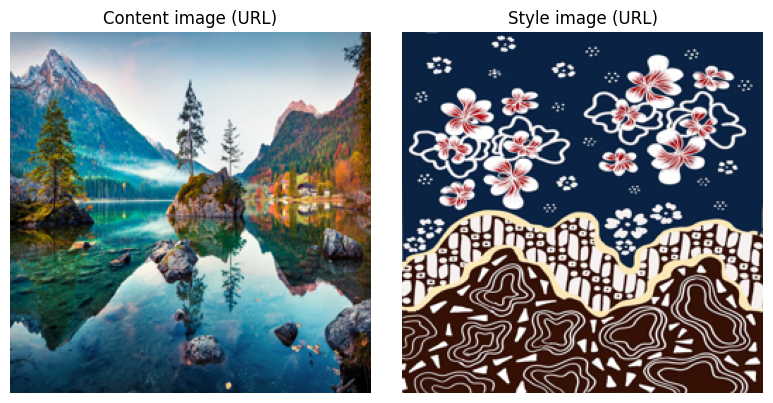

In [10]:
content_img = preprocess(content_pil, device)
style_img   = preprocess(style_pil,   device)

print("content_img:", tuple(content_img.shape), content_img.dtype, content_img.device)
print("style_img  :", tuple(style_img.shape),   style_img.dtype,   style_img.device)

show_images([content_img, style_img], ["Content image", "Style image"])

Mengubah dua gambar awal menjadi tensor, mencetak bentuk dan tipenya, lalu menampilkannya.

### **2.4 Unit Pengujian Bagian 2 (Image I/O)**

In [11]:
# ============================================================
# UJI BAGIAN 2
# ============================================================
print("=" * 50)
print("UJI BAGIAN 2: IMAGE_IO")
print("=" * 50)

# Save pre-downloaded PIL images to disk first so they can be loaded by local paths
content_pil.save(cfg.content_path)
style_pil.save(cfg.style_path)

content_pil = load_image(cfg.content_path, cfg.image_size)
style_pil   = load_image(cfg.style_path,   cfg.image_size)
content_img = preprocess(content_pil, device)
style_img   = preprocess(style_pil,   device)

S = cfg.image_size

# Uji 1: bentuk, dtype, kanal, device, rentang, gradien
for nama, img in [("content_img", content_img), ("style_img", style_img)]:
    assert img.shape == (1, 3, S, S), f"{nama}: bentuk {tuple(img.shape)}"
    assert img.dtype == torch.float32, f"{nama}: dtype {img.dtype}"
    assert img.shape[1] == 3, f"{nama}: jumlah kanal {img.shape[1]}"
    assert img.device.type == device.type, f"{nama}: device {img.device}"
    assert img.min().item() >= 0.0 and img.max().item() <= 1.0, f"{nama}: rentang di luar [0,1]"
    assert img.max().item() > img.min().item(), f"{nama}: gambar konstan (tidak ada variasi)"
    assert not img.requires_grad, f"{nama}: seharusnya requires_grad=False"
    print(f"[Uji 1] {nama}: bentuk {tuple(img.shape)}, {img.dtype}, kanal=3, device={img.device}, "
          f"min={img.min().item():.4f}, max={img.max().item():.4f}, mean={img.mean().item():.4f}: OK")

# Uji 2: hasil load_image berupa PIL RGB berukuran 256x256
for nama, pil in [("content_pil", content_pil), ("style_pil", style_pil)]:
    assert pil.mode == "RGB" and pil.size == (S, S), f"{nama}: mode={pil.mode}, size={pil.size}"
    print(f"[Uji 2] {nama}: mode RGB, ukuran {pil.size}: OK")

# Uji 3: round-trip PIL -> tensor -> PIL harus identik piksel demi piksel
for nama, pil, img in [("content", content_pil, content_img), ("style", style_pil, style_img)]:
    asli = np.array(pil).astype(np.int16)
    balik = np.array(tensor_to_pil(img)).astype(np.int16)
    selisih = int(np.abs(asli - balik).max())
    assert selisih == 0, f"{nama}: selisih maksimum {selisih}"
    print(f"[Uji 3] Round-trip {nama}: selisih piksel maksimum = {selisih}: OK")

# Uji 4: denormalize tidak mengubah tensor yang sudah di [0,1], dan memotong nilai di luar rentang
assert torch.equal(denormalize(content_img), content_img)
tinggi = torch.full((1, 3, 4, 4), 1.5, device=device)
rendah = torch.full((1, 3, 4, 4), -0.5, device=device)
assert denormalize(tinggi).max().item() == 1.0 and denormalize(rendah).min().item() == 0.0
assert tinggi.max().item() == 1.5 and rendah.min().item() == -0.5   # tensor asli tidak berubah
print("[Uji 4] denormalize: nilai valid utuh, nilai di luar rentang dipotong, tensor asli utuh: OK")

# Uji 5: tensor yang punya gradien tetap bisa dikonversi, dan hasilnya terlepas dari graf
g = content_img.clone().requires_grad_(True)
_ = tensor_to_pil(g)
assert denormalize(g).requires_grad is False
assert g.requires_grad is True and g.is_leaf is True
print("[Uji 5] Tensor dengan requires_grad aman dikonversi; tensor asli tetap leaf: OK")

# Uji 6: content dan style benar-benar berbeda
beda = (content_img - style_img).abs().mean().item()
assert beda > 1e-3, "content dan style tampak identik"
print(f"[Uji 6] Rata-rata selisih content vs style = {beda:.4f} (gambar berbeda): OK")

# Uji 7: penanganan error
try:
    load_image("images/tidak_ada.jpg", S)
    raise AssertionError("Seharusnya FileNotFoundError")
except FileNotFoundError:
    print("[Uji 7a] File tidak ada -> FileNotFoundError: OK")
try:
    tensor_to_pil(torch.zeros(3, 4, 4))
    raise AssertionError("Seharusnya AssertionError")
except AssertionError as e:
    if "Seharusnya" in str(e):
        raise
    print("[Uji 7b] Tensor bukan 4 dimensi ditolak: OK")

print("\nSEMUA UJI BAGIAN 2 LULUS")

UJI BAGIAN 2: IMAGE_IO
[Uji 1] content_img: bentuk (1, 3, 256, 256), torch.float32, kanal=3, device=cuda:0, min=0.0000, max=1.0000, mean=0.4584: OK
[Uji 1] style_img: bentuk (1, 3, 256, 256), torch.float32, kanal=3, device=cuda:0, min=0.0000, max=1.0000, mean=0.3674: OK
[Uji 2] content_pil: mode RGB, ukuran (256, 256): OK
[Uji 2] style_pil: mode RGB, ukuran (256, 256): OK
[Uji 3] Round-trip content: selisih piksel maksimum = 0: OK
[Uji 3] Round-trip style: selisih piksel maksimum = 0: OK
[Uji 4] denormalize: nilai valid utuh, nilai di luar rentang dipotong, tensor asli utuh: OK
[Uji 5] Tensor dengan requires_grad aman dikonversi; tensor asli tetap leaf: OK
[Uji 6] Rata-rata selisih content vs style = 0.3823 (gambar berbeda): OK
[Uji 7a] File tidak ada -> FileNotFoundError: OK
[Uji 7b] Tensor bukan 4 dimensi ditolak: OK

SEMUA UJI BAGIAN 2 LULUS


Unit test Bagian 2: memeriksa bentuk, tipe, rentang nilai, hasil bolak-balik PIL ↔ tensor yang identik, serta penolakan input yang salah.


#### **2.5 Dataset Ringan, Augmentasi & Data Loader**

#### **2.5.1 Dataset dan DataLoader**

In [12]:
import glob
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T

DATA_DIR    = "data"
CONTENT_DIR = os.path.join(DATA_DIR, "content")
STYLE_DIR   = os.path.join(DATA_DIR, "style")
os.makedirs(CONTENT_DIR, exist_ok=True)
os.makedirs(STYLE_DIR, exist_ok=True)

CONTENT_SOURCES = [
    ("content_awal.jpg", CONTENT_URL, "pasangan awal (Bagian 2)"),
    ("content_02.jpg", "https://images.unsplash.com/photo-1776871002050-f479a540f7c0?q=80&w=1630&auto=format&fit=crop&ixlib=rb-4.1.0&ixid=NHwxMjA3fDA%3D", "Unsplash"),
    ("content_03.jpg", "https://images.unsplash.com/photo-1506744038136-46273834b3fb?w=700&auto=format&fit=crop&q=60&ixlib=rb-4.1.0&ixid=NHwxMjA3fDA%3D", "Unsplash"),
    ("content_04.jpg", "https://images.unsplash.com/photo-1764957080224-3e560f1cb107?q=80&w=987&auto=format&fit=crop&ixlib=rb-4.1.0&ixid=NHwxMjA3fDA%3D", "Unsplash"),
]
STYLE_SOURCES = [
    ("style_awal.jpg", STYLE_URL, "pasangan awal (Bagian 2)"),
    ("style_02.jpg", "https://images.unsplash.com/photo-1578926375605-eaf7559b1458?w=700&auto=format&fit=crop&q=60&ixlib=rb-4.1.0&ixid=NHwxMjA3fDA%3D", "Unsplash"),
    ("style_03.jpg", "https://images.unsplash.com/photo-1765814142702-52474219184e?w=700&auto=format&fit=crop&q=60&ixlib=rb-4.1.0&ixid=NHwxMjA3fDA%3D", "Unsplash"),
]

def download_images(sources, out_dir):
    headers = {"User-Agent": "Mozilla/5.0"}
    for fname, url, _ in sources:
        path = os.path.join(out_dir, fname)
        if os.path.isfile(path):
            continue
        r = requests.get(url, headers=headers, timeout=15)
        r.raise_for_status()
        Image.open(BytesIO(r.content)).convert("RGB").save(path, quality=95)

download_images(CONTENT_SOURCES, CONTENT_DIR)
download_images(STYLE_SOURCES, STYLE_DIR)
print("content:", sorted(os.listdir(CONTENT_DIR)))
print("style  :", sorted(os.listdir(STYLE_DIR)))

content: ['content_02.jpg', 'content_03.jpg', 'content_04.jpg', 'content_awal.jpg']
style  : ['style_02.jpg', 'style_03.jpg', 'style_awal.jpg']


Menyiapkan folder data/content dan data/style, mendaftar sumber gambar lalu mengunduhnya kalau belum ada.

#### **2.5.2 Ringkasan Dataset, Visualisasi Augmentasi, dan Cek Batch**

In [13]:
IMG_EXT = ("*.jpg", "*.jpeg", "*.png", "*.webp")

class NSTImageDataset(Dataset):
    """Membaca gambar dari folder -> tensor float32 (3,H,W) di [0,1].
    Tanpa normalisasi ImageNet (dilakukan di VGGFeatureExtractor)."""
    def __init__(self, folder: str, image_size: int, augment: bool = False):
        self.paths = sorted(p for ext in IMG_EXT for p in glob.glob(os.path.join(folder, ext)))
        if len(self.paths) == 0:
            raise FileNotFoundError(f"Tidak ada gambar di folder '{folder}'")
        bicubic = T.InterpolationMode.BICUBIC
        if augment:
            ops = [T.RandomResizedCrop(image_size, scale=(0.6, 1.0), ratio=(0.9, 1.1), interpolation=bicubic),
                   T.RandomHorizontalFlip(0.5),
                   T.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1)]
        else:
            ops = [T.Resize(image_size, interpolation=bicubic), T.CenterCrop(image_size)]
        self.transform = T.Compose(ops + [T.ToTensor()])

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.transform(img), os.path.basename(self.paths[i])


def make_loader(folder, image_size, augment=False, batch_size=1, shuffle=False, seed=42):
    g = torch.Generator()
    g.manual_seed(seed)
    ds = NSTImageDataset(folder, image_size, augment)
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, num_workers=0, generator=g)

NSTImageDataset membaca semua gambar dari satu folder dan mengubahnya menjadi tensor [0, 1]. Tanpa augmentasi: Resize sisi pendek lalu CenterCrop, sehingga rasio aspek terjaga. Dengan augmentasi: RandomResizedCrop, flip horizontal, dan ColorJitter ringan. make_loader membungkusnya dengan DataLoader yang seed-nya dikunci.



#### **Ringkasan dataset, visualisasi augmentasi, cek batch**

file                         ukuran asli    mode
content_02.jpg               (1630, 1161)   RGB
content_03.jpg               (700, 467)     RGB
content_04.jpg               (987, 1481)    RGB
content_awal.jpg             (1000, 631)    RGB
style_02.jpg                 (700, 532)     RGB
style_03.jpg                 (700, 883)     RGB
style_awal.jpg               (735, 1041)    RGB


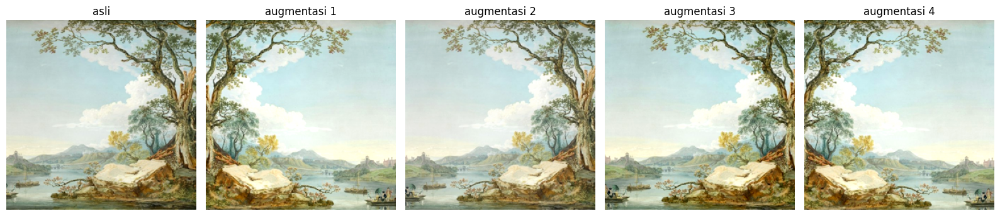

batch: (2, 3, 256, 256) torch.float32 min=0.000 max=0.933 ('content_02.jpg', 'content_03.jpg')


In [14]:
S = cfg.image_size
print(f"{'file':28s} {'ukuran asli':14s} mode")
for folder in (CONTENT_DIR, STYLE_DIR):
    for p in sorted(sum([glob.glob(os.path.join(folder, e)) for e in IMG_EXT], [])):
        with Image.open(p) as im:
            print(f"{os.path.basename(p):28s} {str(im.size):14s} {im.mode}")

# Visualisasi: 1 gambar style asli vs 4 hasil augmentasi
ds_plain = NSTImageDataset(STYLE_DIR, S, augment=False)
ds_aug   = NSTImageDataset(STYLE_DIR, S, augment=True)
set_seed(cfg.seed)
fig, axes = plt.subplots(1, 5, figsize=(16, 3.4))
axes[0].imshow(ds_plain[0][0].permute(1, 2, 0).numpy()); axes[0].set_title("asli")
for k in range(1, 5):
    axes[k].imshow(ds_aug[0][0].permute(1, 2, 0).numpy()); axes[k].set_title(f"augmentasi {k}")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(cfg.output_dir, "augmentasi_contoh.png"), dpi=150, bbox_inches="tight")
plt.show()

# Cek batch dari DataLoader
loader = make_loader(CONTENT_DIR, S, batch_size=min(2, len(os.listdir(CONTENT_DIR))))
xb, names = next(iter(loader))
print("batch:", tuple(xb.shape), xb.dtype, f"min={xb.min():.3f} max={xb.max():.3f}", names)

Mencetak ukuran asli setiap gambar, menampilkan satu gambar style beserta empat hasil augmentasinya, lalu mengambil satu batch dari DataLoader untuk memeriksa bentuknya.

**Dokumentasi Dataset**

| File | Jenis | Sumber | Lisensi | Ukuran asli |
|---|---|---|---|---|
| content_awal.jpg | content | bioneers.org (shutterstock_747646759.jpg) | Tidak diketahui; hanya untuk keperluan akademik non-komersial | 1000×631 |
| content_02.jpg | content | Unsplash (photo-1776871002050-f479a540f7c0) | Unsplash License | 1630×1161 |
| content_03.jpg | content | Unsplash (photo-1506744038136-46273834b3fb) | Unsplash License | 700×467 |
| content_04.jpg | content | Unsplash (photo-1764957080224-3e560f1cb107) | Unsplash License | 987×1481 |
| style_awal.jpg | style | i.pinimg.com (89bff400f362f0142027fb0752cb7166.jpg) | Tidak diketahui; hanya untuk keperluan akademik non-komersial | 735×1041 |
| style_02.jpg | style | Unsplash (photo-1578926375605-eaf7559b1458) | Unsplash License | 700×532 |
| style_03.jpg | style | Unsplash (photo-1765814142702-52474219184e) | Unsplash License | 700×883 |

**Pemilihan gambar:** gambar content dan style dipilih secara bebas (acak) dari Unsplash, tanpa kriteria khusus, karena NST tidak bergantung pada dataset tertentu. Gambar memiliki orientasi dan ukuran yang bervariasi (landscape dan portrait; sisi pendek 467–1161 piksel), sehingga pipeline Resize + CenterCrop teruji pada berbagai rasio aspek. Karena dipilih tanpa seleksi, tidak semua gambar style cocok dengan konfigurasi baseline (lihat Bagian 9 dan Keterbatasan).

**Pipeline:** RGB → Resize sisi pendek 256 (bicubic) → CenterCrop 256 → ToTensor [0,1] → (di model) normalisasi ImageNet.

**Augmentasi (opsional):** RandomResizedCrop 0.6–1.0, flip horizontal, ColorJitter ringan. Tujuannya menambah variasi tekstur style dan pasangan uji; tidak mengubah arsitektur NST.

**Catatan:** eksperimen Bagian 3–8 memakai pasangan awal lewat `load_image_from_url`, yang memaksa gambar menjadi persegi 256×256 dengan resize langsung (rasio aspek tidak dijaga). Bagian 9 memakai `NSTImageDataset` (Resize sisi pendek + CenterCrop). Karena itu angka loss Bagian 9 tidak sebanding dengan E0.

#### **2.5.3 Unit Pengujian Dataset**

In [15]:
import tempfile
print("=" * 50); print("UJI BAGIAN 2.5: DATASET & LOADER"); print("=" * 50)

# Uji 1: shape, dtype, rentang
assert xb.ndim == 4 and xb.shape[1:] == (3, S, S) and xb.dtype == torch.float32
assert xb.min().item() >= 0.0 and xb.max().item() <= 1.0
print("[Uji 1] Batch (B,3,S,S), float32, di [0,1]: OK")

# Uji 2: gambar non-persegi -> output persegi, tanpa distorsi (kiri merah, kanan biru)
with tempfile.TemporaryDirectory() as d:
    im = Image.new("RGB", (300, 200), (255, 0, 0))
    im.paste(Image.new("RGB", (150, 200), (0, 0, 255)), (150, 0))
    im.save(os.path.join(d, "t.png"))
    x, _ = NSTImageDataset(d, S)[0]
    assert x.shape == (3, S, S)
    assert x[0, S // 2, 5] > 0.9 and x[2, S // 2, S - 5] > 0.9
print("[Uji 2] Gambar 300x200 -> (3,S,S) via resize+center crop, tata letak utuh: OK")

# Uji 3: augmentasi reproducible dengan seed sama, dan bervariasi dengan seed beda
set_seed(cfg.seed); a = ds_aug[0][0]
set_seed(cfg.seed); b = ds_aug[0][0]
assert torch.equal(a, b)
set_seed(cfg.seed + 1); c = ds_aug[0][0]
assert not torch.equal(a, c)
print("[Uji 3] Augmentasi reproducible (seed sama) dan bervariasi (seed beda): OK")

# Uji 4: folder kosong ditolak
with tempfile.TemporaryDirectory() as d:
    try:
        NSTImageDataset(d, S); raise AssertionError("Seharusnya error")
    except FileNotFoundError:
        pass
print("[Uji 4] Folder kosong memicu FileNotFoundError: OK")

set_seed(cfg.seed)
print("\nUJI 1-4 BAGIAN 2.5 LULUS (Uji 5 dijalankan setelah Bagian 3)")

UJI BAGIAN 2.5: DATASET & LOADER
[Uji 1] Batch (B,3,S,S), float32, di [0,1]: OK
[Uji 2] Gambar 300x200 -> (3,S,S) via resize+center crop, tata letak utuh: OK
[Uji 3] Augmentasi reproducible (seed sama) dan bervariasi (seed beda): OK
[Uji 4] Folder kosong memicu FileNotFoundError: OK

UJI 1-4 BAGIAN 2.5 LULUS (Uji 5 dijalankan setelah Bagian 3)


Unit test dataset: bentuk batch benar, gambar non-persegi tidak terdistorsi setelah crop, augmentasi reproducible dengan seed sama, dan folder kosong memicu error.

## **Bagian 3: Ekstraksi Fitur (Feature Extractor)**

In [16]:
# ============================================================
# BAGIAN 3: FEATURE_EXTRACTOR
# (torch, numpy, os sudah diimpor di Bagian 1; tidak diimpor ulang)
# ============================================================
import gc
import torch.nn as nn
from torchvision.models import vgg19, VGG19_Weights

Impor torch.nn dan VGG-19 beserta bobot pralatih dari torchvision.

### **3.1 Pemetaan Layer & Kelas VGGFeatureExtractor**

In [17]:
# Konstanta tunggal normalisasi ImageNet (hanya dipakai di Bagian 3)
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)

# Pemetaan nama layer NST -> indeks di torchvision vgg19().features (didefinisikan SEKALI)
LAYER_MAP = {
    "conv1_1": 0,  "conv1_2": 2,
    "conv2_1": 5,  "conv2_2": 7,
    "conv3_1": 10, "conv3_2": 12, "conv3_3": 14, "conv3_4": 16,
    "conv4_1": 19, "conv4_2": 21, "conv4_3": 23, "conv4_4": 25,
    "conv5_1": 28, "conv5_2": 30, "conv5_3": 32, "conv5_4": 34,
}


class VGGFeatureExtractor(nn.Module):
    """Ekstraktor fitur VGG-19 pralatih (beku).
    Input : tensor (N, 3, H, W) di rentang [0, 1]
    Output: dict {nama_layer: fitur (N, C, H', W')}  (output konvolusi, sebelum ReLU)
    Hanya melakukan forward. Tidak menghitung loss."""

    def __init__(self, layer_names, pooling: str = "max"):
        super().__init__()
        # --- validasi konfigurasi (sebelum mengunduh apa pun) ---
        unknown = [n for n in layer_names if n not in LAYER_MAP]
        if unknown:
            raise ValueError(f"Nama layer tidak dikenal: {unknown}. Pilihan: {list(LAYER_MAP)}")
        if pooling not in ("max", "avg"):
            raise ValueError("pooling harus 'max' atau 'avg'")

        self.layer_names = list(dict.fromkeys(layer_names))        # unik, urutan terjaga
        self.index_to_name = {LAYER_MAP[n]: n for n in self.layer_names}
        last_index = max(self.index_to_name)

        # --- muat VGG-19 pralatih ImageNet (tidak pernah diganti bobot acak) ---
        features = self._load_pretrained_features()

        # --- verifikasi pemetaan: setiap indeks harus layer Conv2d ---
        for name, idx in LAYER_MAP.items():
            assert isinstance(features[idx], nn.Conv2d), \
                f"LAYER_MAP['{name}']={idx} bukan Conv2d, melainkan {type(features[idx]).__name__}"

        # --- bangun daftar layer sampai layer terdalam yang dibutuhkan ---
        layers = []
        for layer in features[: last_index + 1]:
            if isinstance(layer, nn.ReLU):
                layer = nn.ReLU(inplace=False)                     # cegah fitur tersimpan rusak
            elif isinstance(layer, nn.MaxPool2d) and pooling == "avg":
                layer = nn.AvgPool2d(kernel_size=2, stride=2)
            layers.append(layer)
        self.layers = nn.ModuleList(layers)
        self.pooling = pooling

        # --- normalisasi ImageNet sebagai buffer (ikut .to(device), bukan parameter) ---
        mean = torch.tensor(IMAGENET_MEAN, dtype=torch.float32).view(1, 3, 1, 1)
        std  = torch.tensor(IMAGENET_STD,  dtype=torch.float32).view(1, 3, 1, 1)
        self.register_buffer("mean", mean, persistent=False)
        self.register_buffer("std",  std,  persistent=False)

        # --- bekukan bobot dan set mode evaluasi ---
        for p in self.parameters():
            p.requires_grad_(False)
        self.eval()

    @staticmethod
    def _load_pretrained_features() -> nn.Sequential:
        """Memuat vgg19().features dengan bobot ImageNet. torchvision memakai cache,
        sehingga bobot tidak diunduh ulang jika sudah ada di runtime."""
        try:
            model = vgg19(weights=VGG19_Weights.IMAGENET1K_V1, progress=True)
        except Exception as e:
            raise RuntimeError(
                "Gagal memuat bobot pralatih VGG-19 (ImageNet). Periksa koneksi internet Colab "
                "lain jalankan ulang sel ini. Bobot acak TIDAK dipakai sebagai pengganti."
            ) from e
        return model.features

    def train(self, mode: bool = True):
        """Ekstraktor selalu tetap di mode evaluasi, bahkan jika .train() terpanggil."""
        return super().train(False)

    def normalize(self, x: torch.Tensor) -> torch.Tensor:
        """[0,1] -> ternormalisasi ImageNet. Menghasilkan tensor BARU (input tidak diubah)."""
        assert x.ndim == 4 and x.shape[1] == 3, f"Diharapkan (N,3,H,W), dapat {tuple(x.shape)}"
        return (x - self.mean) / self.std

    def forward(self, x: torch.Tensor) -> dict:
        x = self.normalize(x)
        feats = {}
        for i, layer in enumerate(self.layers):
            x = layer(x)
            if i in self.index_to_name:
                feats[self.index_to_name[i]] = x
        return feats

Berisi konstanta mean dan std ImageNet, peta nama layer (misalnya conv4_2) ke indeks di VGG-19, dan kelas VGGFeatureExtractor. Kelas ini memuat VGG-19 pralatih ImageNet, memotongnya sampai layer terdalam yang dibutuhkan, membekukan bobotnya, dan menjalankannya selalu di mode eval. Normalisasi ImageNet dilakukan di dalam kelas ini. Outputnya berupa dictionary fitur konvolusi (sebelum ReLU) untuk tiap layer yang diminta. Pooling bisa dipilih max atau avg.

### **3.2 Inisialisasi Model & Analisis Parameter**

In [18]:
CONTENT_LAYERS = cfg.content_layers
STYLE_LAYERS   = cfg.style_layers
ALL_LAYERS     = list(dict.fromkeys(CONTENT_LAYERS + STYLE_LAYERS))

extractor = VGGFeatureExtractor(ALL_LAYERS, pooling=cfg.pooling).to(device)

# --- periksa konfigurasi ---
n_total     = sum(p.numel() for p in extractor.parameters())
n_trainable = sum(p.numel() for p in extractor.parameters() if p.requires_grad)

print("=" * 85)
print(" VGG FEATURE EXTRACTOR DIAGNOSTIC ".center(85, "="))
print("=" * 85)
print(f"  Pooling Configuration   : {cfg.pooling}")
print(f"  Requested Target Layers : {ALL_LAYERS}")
print(f"  Is Training Mode?       : {extractor.training}")
print(f"  Total Parameters        : {n_total:,}")
print(f"  Trainable Parameters    : {n_trainable:,}")
print(f"  Device Location         : {next(extractor.parameters()).device}")
print("-" * 85)
print(" NETWORK ARCHITECTURE & NST LAYER MAPPING ".center(85, "-"))
print("-" * 85)
for i, layer in enumerate(extractor.layers):
    tanda = f"<=== NST TARGET: {extractor.index_to_name[i]}" if i in extractor.index_to_name else ""
    print(f"  [{i:2d}] {str(layer):70s} {tanda}")
print("=" * 85)

Downloading: "https://download.pytorch.org/models/vgg19-dcbb9e9d.pth" to /root/.cache/torch/hub/checkpoints/vgg19-dcbb9e9d.pth


100%|██████████| 548M/548M [00:08<00:00, 70.5MB/s]


========================== VGG FEATURE EXTRACTOR DIAGNOSTIC =========================
  Pooling Configuration   : max
  Requested Target Layers : ['conv4_2', 'conv1_1', 'conv2_1', 'conv3_1', 'conv4_1', 'conv5_1']
  Is Training Mode?       : False
  Total Parameters        : 12,944,960
  Trainable Parameters    : 0
  Device Location         : cuda:0
-------------------------------------------------------------------------------------
---------------------- NETWORK ARCHITECTURE & NST LAYER MAPPING ---------------------
-------------------------------------------------------------------------------------
  [ 0] Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))       <=== NST TARGET: conv1_1
  [ 1] ReLU()                                                                 
  [ 2] Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))      
  [ 3] ReLU()                                                                 
  [ 4] MaxPool2d(kernel_size=2, stride=2, padding=0

Membuat extractor untuk layer content dan style, lalu mencetak diagnostik: jumlah parameter, bahwa semuanya tidak bisa dilatih, dan susunan layer VGG beserta layer yang menjadi target.

### **3.3 Ekstraksi Fitur dari Gambar Target**

In [19]:
# Fitur target dihitung SEKALI tanpa gradien (aturan D.5).
with torch.no_grad():
    content_feats = extractor(content_img)
    style_feats   = extractor(style_img)

def ringkas_fitur(nama_set, feats):
    print(f"\nFitur {nama_set}:")
    print(f"  {'layer':8s} {'bentuk':22s} {'dtype':14s} {'grad':6s} {'min':>9s} {'max':>9s} {'mean':>9s}")
    for name, f in feats.items():
        print(f"  {name:8s} {str(tuple(f.shape)):22s} {str(f.dtype):14s} {str(f.requires_grad):6s} "
              f"{f.min().item():9.3f} {f.max().item():9.3f} {f.mean().item():9.3f}")

ringkas_fitur("content_feats", content_feats)
ringkas_fitur("style_feats", style_feats)

print("\ncontent_img tidak berubah -> min/max:",
      f"{content_img.min().item():.4f}/{content_img.max().item():.4f}")


Fitur content_feats:
  layer    bentuk                 dtype          grad         min       max      mean
  conv1_1  (1, 64, 256, 256)      torch.float32  False    -12.402    13.730     0.048
  conv2_1  (1, 128, 128, 128)     torch.float32  False    -65.619    36.745    -1.308
  conv3_1  (1, 256, 64, 64)       torch.float32  False   -126.429    70.457    -3.004
  conv4_1  (1, 512, 32, 32)       torch.float32  False   -130.493    99.004    -9.094
  conv4_2  (1, 512, 32, 32)       torch.float32  False    -78.392    86.218    -8.464
  conv5_1  (1, 512, 16, 16)       torch.float32  False    -43.058    43.056    -4.355

Fitur style_feats:
  layer    bentuk                 dtype          grad         min       max      mean
  conv1_1  (1, 64, 256, 256)      torch.float32  False    -16.850    17.302     0.068
  conv2_1  (1, 128, 128, 128)     torch.float32  False   -101.525    56.923    -4.069
  conv3_1  (1, 256, 64, 64)       torch.float32  False   -148.712   117.281    -6.663
  conv4_1  (

Menghitung fitur content dan style satu kali saja tanpa gradien, karena keduanya hanya target yang tidak berubah. Lalu mencetak ringkasan bentuk dan statistik tiap fitur.

### **3.4 Unit Pengujian Bagian 3 (Feature Extractor)**

In [20]:
# ============================================================
# UJI BAGIAN 3
# ============================================================
print("=" * 60)
print("UJI BAGIAN 3: FEATURE_EXTRACTOR")
print("=" * 60)
S = cfg.image_size

# --- Uji 1: bobot pretrained ImageNet, bukan acak ---
ref_sd = VGG19_Weights.IMAGENET1K_V1.get_state_dict(progress=True, check_hash=True)
n_conv = 0
for i, layer in enumerate(extractor.layers):
    if isinstance(layer, nn.Conv2d):
        assert torch.equal(layer.weight.detach().cpu(), ref_sd[f"features.{i}.weight"]), f"bobot conv idx {i} beda"
        assert torch.equal(layer.bias.detach().cpu(),   ref_sd[f"features.{i}.bias"]),   f"bias conv idx {i} beda"
        n_conv += 1
print(f"[Uji 1a] {n_conv} layer konvolusi identik dengan checkpoint ImageNet resmi: OK")

torch.manual_seed(123)
acak = nn.Conv2d(3, 64, 3, padding=1)
assert not torch.equal(extractor.layers[0].weight.detach().cpu(), acak.weight.detach())
set_seed(cfg.seed)  # kembalikan seed proyek
print("[Uji 1b] Bobot conv1_1 berbeda dari inisialisasi acak: OK")

# --- Uji 2: mode evaluasi ---
assert extractor.training is False and all(not m.training for m in extractor.modules())
extractor.train()                       # coba paksa ke mode train
assert extractor.training is False      # tetap eval
print("[Uji 2] Seluruh modul di mode eval (dan tetap eval setelah .train()): OK")

# --- Uji 3: semua parameter beku ---
assert n_total > 0
assert all(not p.requires_grad for p in extractor.parameters())
print(f"[Uji 3] {n_total:,} parameter, semuanya requires_grad=False: OK")

# --- Uji 4: normalisasi ImageNet benar ---
mean_ref = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
std_ref  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)
assert extractor.mean.shape == (1, 3, 1, 1) and extractor.std.shape == (1, 3, 1, 1)
assert torch.allclose(extractor.mean, mean_ref) and torch.allclose(extractor.std, std_ref)
assert extractor.mean.device.type == device.type
x_mean = mean_ref.expand(1, 3, 8, 8).clone()
assert extractor.normalize(x_mean).abs().max().item() < 1e-6          # nilai = mean -> 0
x_one = torch.ones(1, 3, 8, 8, device=device)
assert torch.allclose(extractor.normalize(x_one), ((1 - mean_ref) / std_ref).expand(1, 3, 8, 8), atol=1e-6)
print("[Uji 4] Mean/std ImageNet benar, broadcasting (1,3,1,1) benar, hasil normalisasi sesuai rumus: OK")

# --- Uji 5: normalisasi/forward tidak mengubah input asli ---
c_before = content_img.clone(); s_before = style_img.clone()
with torch.no_grad():
    _ = extractor(content_img); _ = extractor(style_img)
assert torch.equal(content_img, c_before) and torch.equal(style_img, s_before)
assert content_img.min().item() >= 0 and content_img.max().item() <= 1
assert style_img.min().item() >= 0 and style_img.max().item() <= 1
assert not content_img.requires_grad and not style_img.requires_grad
print("[Uji 5] content_img/style_img tidak berubah, masih [0,1], requires_grad=False: OK")

# --- Uji 6: semua layer ditemukan dan pemetaan benar ---
for feats, nama in [(content_feats, "content_feats"), (style_feats, "style_feats")]:
    assert set(feats.keys()) == set(ALL_LAYERS), f"{nama}: {set(feats.keys())}"
for n in ALL_LAYERS:
    assert isinstance(extractor.layers[LAYER_MAP[n]], nn.Conv2d)
assert all(l in content_feats for l in CONTENT_LAYERS)
assert all(l in style_feats for l in STYLE_LAYERS)
print(f"[Uji 6] Semua layer {ALL_LAYERS} ditemukan dan berupa Conv2d: OK")

# --- Uji 7: bentuk fitur sesuai arsitektur (dihitung terpisah dari kode kelas) ---
channels = [64, 128, 256, 512, 512]
for feats, nama in [(content_feats, "content"), (style_feats, "style")]:
    for n, f in feats.items():
        blok = int(n[4])                                   # "conv4_2" -> 4
        harapan = (1, channels[blok - 1], S // 2 ** (blok - 1), S // 2 ** (blok - 1))
        assert tuple(f.shape) == harapan, f"{nama}/{n}: {tuple(f.shape)} != {harapan}"
        assert f.dtype == torch.float32 and f.device.type == device.type
print("[Uji 7] Bentuk fitur sesuai (C: 64/128/256/512/512, H'=W'=S/2^(blok-1)): OK")

# --- Uji 8: tidak ada NaN/Inf ---
for feats, nama in [(content_feats, "content"), (style_feats, "style")]:
    for n, f in feats.items():
        assert torch.isfinite(f).all(), f"{nama}/{n} mengandung NaN/Inf"
print("[Uji 8] Tidak ada NaN/Inf pada fitur: OK")

# --- Uji 9: ReLU tidak in-place, fitur pra-ReLU, hasil deterministik ---
assert all(not l.inplace for l in extractor.layers if isinstance(l, nn.ReLU))
assert content_feats["conv4_2"].min().item() < 0, "fitur seharusnya pra-ReLU (ada nilai negatif)"
with torch.no_grad():
    ulang = extractor(content_img)
for n in ALL_LAYERS:
    assert torch.equal(ulang[n], content_feats[n]), f"fitur {n} berubah antar-forward"
print("[Uji 9] ReLU non-in-place, fitur pra-ReLU (ada nilai negatif), forward berulang konsisten: OK")

# --- Uji 10: pooling sesuai cfg.pooling ---
kelas_pool = nn.MaxPool2d if cfg.pooling == "max" else nn.AvgPool2d
pools = [l for l in extractor.layers if isinstance(l, (nn.MaxPool2d, nn.AvgPool2d))]
assert len(pools) == 4 and all(isinstance(p, kelas_pool) for p in pools)
print(f"[Uji 10a] 4 pooling bertipe {kelas_pool.__name__} sesuai cfg.pooling='{cfg.pooling}': OK")

ext_avg = VGGFeatureExtractor(ALL_LAYERS, pooling="avg").to(device)
assert all(isinstance(l, nn.AvgPool2d) for l in ext_avg.layers if isinstance(l, (nn.MaxPool2d, nn.AvgPool2d)))
with torch.no_grad():
    fa = ext_avg(content_img)
assert all(fa[n].shape == content_feats[n].shape for n in ALL_LAYERS)
del ext_avg, fa; gc.collect()
if device.type == "cuda": torch.cuda.empty_cache()
print("[Uji 10b] Varian pooling='avg' bisa dibuat, bentuk fitur sama (tidak dipakai selanjutnya): OK")

# --- Uji 11: validasi error ---
for nama, kw in [("layer salah", dict(layer_names=["conv9_9"])),
                 ("pooling salah", dict(layer_names=["conv1_1"], pooling="min"))]:
    try:
        VGGFeatureExtractor(**kw)
        raise AssertionError(f"Seharusnya ValueError: {nama}")
    except ValueError:
        print(f"[Uji 11] Ekstraktor menolak '{nama}' dengan ValueError: OK")

# --- Uji 12: gradien mengalir ke input (tensor uji terpisah) ---
x_test = content_img.clone().detach().requires_grad_(True)
f_test = extractor(x_test)                                   # TANPA no_grad
assert all(f.requires_grad for f in f_test.values())
loss_uji = sum(f.pow(2).mean() for f in f_test.values())
loss_uji.backward()
assert x_test.grad is not None and x_test.grad.shape == x_test.shape
assert torch.isfinite(x_test.grad).all() and x_test.grad.abs().sum().item() > 0
assert all(p.grad is None for p in extractor.parameters())   # bobot VGG tidak menerima gradien
assert not content_img.requires_grad and content_img.grad is None
print(f"[Uji 12] Gradien ke input: bentuk {tuple(x_test.grad.shape)}, "
      f"|grad| rata-rata={x_test.grad.abs().mean().item():.3e}; bobot VGG tanpa gradien; "
      f"content_img asli tidak tersentuh: OK")

print("\nSEMUA UJI BAGIAN 3 LULUS")

UJI BAGIAN 3: FEATURE_EXTRACTOR
[Uji 1a] 13 layer konvolusi identik dengan checkpoint ImageNet resmi: OK
[Uji 1b] Bobot conv1_1 berbeda dari inisialisasi acak: OK
[Uji 2] Seluruh modul di mode eval (dan tetap eval setelah .train()): OK
[Uji 3] 12,944,960 parameter, semuanya requires_grad=False: OK
[Uji 4] Mean/std ImageNet benar, broadcasting (1,3,1,1) benar, hasil normalisasi sesuai rumus: OK
[Uji 5] content_img/style_img tidak berubah, masih [0,1], requires_grad=False: OK
[Uji 6] Semua layer ['conv4_2', 'conv1_1', 'conv2_1', 'conv3_1', 'conv4_1', 'conv5_1'] ditemukan dan berupa Conv2d: OK
[Uji 7] Bentuk fitur sesuai (C: 64/128/256/512/512, H'=W'=S/2^(blok-1)): OK
[Uji 8] Tidak ada NaN/Inf pada fitur: OK
[Uji 9] ReLU non-in-place, fitur pra-ReLU (ada nilai negatif), forward berulang konsisten: OK
[Uji 10a] 4 pooling bertipe MaxPool2d sesuai cfg.pooling='max': OK
[Uji 10b] Varian pooling='avg' bisa dibuat, bentuk fitur sama (tidak dipakai selanjutnya): OK
[Uji 11] Ekstraktor menolak 'l

Unit test extractor: bobot sama dengan checkpoint ImageNet resmi, mode eval, semua parameter beku, normalisasi benar, dan bentuk fitur sesuai.

### **3.5 Uji Integrasi Dataset ke Feature Extractor**

In [21]:
xb, names = next(iter(make_loader(CONTENT_DIR, cfg.image_size,
                                  batch_size=min(2, len(os.listdir(CONTENT_DIR))))))

with torch.no_grad():
    f = extractor(xb.to(device))

assert f["conv4_2"].shape == (xb.shape[0], 512, cfg.image_size // 8, cfg.image_size // 8)
assert f["conv1_1"].shape == (xb.shape[0], 64, cfg.image_size, cfg.image_size)
assert all(torch.isfinite(v).all() for v in f.values())
print(f"[Uji 5] Batch {tuple(xb.shape)} dari loader masuk ke extractor tanpa error; "
      f"conv4_2 = {tuple(f['conv4_2'].shape)}: OK")

[Uji 5] Batch (2, 3, 256, 256) dari loader masuk ke extractor tanpa error; conv4_2 = (2, 512, 32, 32): OK


Uji integrasi: batch dari DataLoader bisa langsung masuk ke extractor tanpa error, dengan bentuk fitur yang sesuai.

## **Bagian 4: Content Loss**

In [22]:
# ============================================================
# BAGIAN 4: CONTENT_LOSS
# ============================================================
import torch.nn.functional as F

Impor torch.nn.functional untuk fungsi MSE.

### **4.1 Formulasi Fungsi Content Loss**

In [23]:
def content_loss(gen_feats: dict, content_feats: dict, layers: list) -> torch.Tensor:
    """Content Loss = MSE (reduction='mean') antara fitur gambar yang dibandingkan
    dan fitur target content, pada layer-layer di `layers`.
    Jika ada beberapa layer, hasilnya dirata-rata antar layer.
    - gen_feats    : dict fitur dari extractor(gambar). TIDAK di-detach (gradien mengalir).
    - content_feats: dict fitur target. Di-detach di sini sebagai pengaman.
    Output: tensor skalar float32."""
    if len(layers) == 0:
        raise ValueError("layers tidak boleh kosong")
    losses = []
    for name in layers:
        if name not in gen_feats or name not in content_feats:
            raise KeyError(f"Layer '{name}' tidak ada di gen_feats atau content_feats")
        g = gen_feats[name]
        t = content_feats[name].detach()                 # target tidak ikut graf gradien
        if g.shape != t.shape:
            raise ValueError(f"Bentuk beda pada '{name}': {tuple(g.shape)} vs {tuple(t.shape)}")
        losses.append(F.mse_loss(g, t, reduction="mean"))
    return torch.stack(losses).mean()

Content Loss adalah rata-rata selisih kuadrat (MSE) antara fitur gambar yang sedang dioptimasi dan fitur target content di layer conv4_2. Semakin kecil, semakin mirip isi gambarnya dengan content. Fitur target dilepas dari graf gradien agar hanya gambar hasil yang diperbarui.

### **4.2 Unit Pengujian Bagian 4 (Content Loss)**

In [24]:
# ============================================================
# UJI BAGIAN 4
# ============================================================
print("=" * 60)
print("UJI BAGIAN 4: CONTENT_LOSS")
print("=" * 60)

c_before = content_img.clone(); s_before = style_img.clone()

# Uji 1: target dari content_img via extractor, terlepas dari graf
with torch.no_grad():
    target_check = extractor(content_img)
assert all(not v.requires_grad for v in target_check.values())
assert all(not v.requires_grad for v in content_feats.values())
for n in ALL_LAYERS:
    assert torch.equal(target_check[n], content_feats[n]), f"content_feats[{n}] tidak konsisten"
print("[Uji 1] Target content_feats = extractor(content_img), tanpa gradien: OK")

# Uji 2: loss gambar terhadap dirinya sendiri = tepat 0
with torch.no_grad():
    gen_feats_self = extractor(content_img)
l_self = content_loss(gen_feats_self, content_feats, CONTENT_LAYERS)
assert l_self.ndim == 0 and l_self.dtype == torch.float32 and l_self.device.type == device.type
assert l_self.item() == 0.0, f"loss diri sendiri = {l_self.item()}"
print(f"[Uji 2] Content loss content vs dirinya = {l_self.item()} (skalar float32, di {l_self.device}): OK")

# Uji 3: loss content vs style positif dan finite
l_cs = content_loss(style_feats, content_feats, CONTENT_LAYERS)
assert torch.isfinite(l_cs).all() and l_cs.item() > 0
print(f"[Uji 3] Content loss (fitur style vs target content) = {l_cs.item():.6f}: positif, finite: OK")

# Uji 4: sesuai rumus manual MSE-mean, dan hubungan dengan sum
a, b = style_feats["conv4_2"], content_feats["conv4_2"]
manual_mean = ((a - b) ** 2).mean()
manual_sum  = ((a - b) ** 2).sum()
N = a.numel()
assert torch.allclose(l_cs, manual_mean, rtol=1e-5)
assert torch.allclose(manual_sum / N, l_cs, rtol=1e-4)
print(f"[Uji 4] Sesuai rumus manual. N = {N:,}; sum = {manual_sum.item():.2f}; "
      f"sum/N = {(manual_sum / N).item():.6f} = loss mean: OK")

# Uji 5: beberapa layer -> rata-rata antar layer
l_a  = content_loss(style_feats, content_feats, ["conv4_2"])
l_b  = content_loss(style_feats, content_feats, ["conv1_1"])
l_ab = content_loss(style_feats, content_feats, ["conv4_2", "conv1_1"])
assert torch.allclose(l_ab, (l_a + l_b) / 2, rtol=1e-5)
print(f"[Uji 5] Dua layer: {l_ab.item():.6f} = rata-rata ({l_a.item():.6f}, {l_b.item():.6f}): OK")

# Uji 6: gradien mengalir ke input (tensor uji terpisah, awal = salinan style_img)
x_test = style_img.clone().detach().requires_grad_(True)
loss6 = content_loss(extractor(x_test), content_feats, CONTENT_LAYERS)   # TANPA no_grad
assert loss6.requires_grad
loss6.backward()
assert x_test.grad is not None and x_test.grad.shape == x_test.shape
assert torch.isfinite(x_test.grad).all() and x_test.grad.abs().sum().item() > 0
print(f"[Uji 6] Gradien ke input: bentuk {tuple(x_test.grad.shape)}, "
      f"|grad| rata-rata = {x_test.grad.abs().mean().item():.3e}: OK")

# Uji 7: target di-detach di dalam fungsi (target ber-gradien tidak menerima gradien)
tgt = {k: v.clone().requires_grad_(True) for k, v in content_feats.items()}
x2 = style_img.clone().detach().requires_grad_(True)
loss7 = content_loss(extractor(x2), tgt, CONTENT_LAYERS)
loss7.backward()
assert all(t.grad is None for t in tgt.values())
assert torch.allclose(x2.grad, x_test.grad, rtol=1e-4, atol=1e-8)
print("[Uji 7] Target tidak menerima gradien; gradien input sama dengan Uji 6: OK")

# Uji 8: awal dari content_img -> loss ~0 dan gradien ~0 (penting untuk init_mode='content')
x3 = content_img.clone().detach().requires_grad_(True)
loss8 = content_loss(extractor(x3), content_feats, CONTENT_LAYERS)
loss8.backward()
assert loss8.item() < 1e-8, f"loss awal = {loss8.item()}"
assert x3.grad.abs().max().item() < 1e-6, f"|grad| maks = {x3.grad.abs().max().item()}"
print(f"[Uji 8] Awal = content_img: loss = {loss8.item():.2e}, |grad| maks = "
      f"{x3.grad.abs().max().item():.2e} (gradien content ~0 di awal): OK")

# Uji 9: penanganan error
for nama, fn, exc in [
    ("layer tidak ada",    lambda: content_loss(style_feats, content_feats, ["conv9_9"]), KeyError),
    ("bentuk tidak cocok", lambda: content_loss({"conv4_2": content_feats["conv1_1"]},
                                                 content_feats, ["conv4_2"]),            ValueError),
    ("layers kosong",      lambda: content_loss(style_feats, content_feats, []),         ValueError),
]:
    try:
        fn()
        raise AssertionError(f"Seharusnya {exc.__name__}: {nama}")
    except exc:
        print(f"[Uji 9] '{nama}' ditolak dengan {exc.__name__}: OK")

# Uji 10: VGG tetap beku, input asli utuh
assert extractor.training is False
assert all(not p.requires_grad for p in extractor.parameters())
assert all(p.grad is None for p in extractor.parameters())
assert torch.equal(content_img, c_before) and torch.equal(style_img, s_before)
assert content_img.grad is None and style_img.grad is None
assert not content_img.requires_grad and not style_img.requires_grad
print("[Uji 10] VGG tetap beku & eval, tanpa .grad; content_img/style_img tidak berubah: OK")

print("\nSEMUA UJI BAGIAN 4 LULUS")

UJI BAGIAN 4: CONTENT_LOSS
[Uji 1] Target content_feats = extractor(content_img), tanpa gradien: OK
[Uji 2] Content loss content vs dirinya = 0.0 (skalar float32, di cuda:0): OK
[Uji 3] Content loss (fitur style vs target content) = 788.889648: positif, finite: OK
[Uji 4] Sesuai rumus manual. N = 524,288; sum = 413605376.00; sum/N = 788.889648 = loss mean: OK
[Uji 5] Dua layer: 397.133881 = rata-rata (788.889648, 5.378084): OK
[Uji 6] Gradien ke input: bentuk (1, 3, 256, 256), |grad| rata-rata = 1.840e-01: OK
[Uji 7] Target tidak menerima gradien; gradien input sama dengan Uji 6: OK
[Uji 8] Awal = content_img: loss = 0.00e+00, |grad| maks = 0.00e+00 (gradien content ~0 di awal): OK
[Uji 9] 'layer tidak ada' ditolak dengan KeyError: OK
[Uji 9] 'bentuk tidak cocok' ditolak dengan ValueError: OK
[Uji 9] 'layers kosong' ditolak dengan ValueError: OK
[Uji 10] VGG tetap beku & eval, tanpa .grad; content_img/style_img tidak berubah: OK

SEMUA UJI BAGIAN 4 LULUS


Unit test content loss: nilainya nol kalau gambar dibandingkan dengan dirinya sendiri, sesuai rumus manual, gradien mengalir ke input, dan input yang salah ditolak.

## **Bagian 5: Gram Matrix & Style Loss**

In [25]:
# ============================================================
# BAGIAN 5: GRAM MATRIX & STYLE_LOSS
# (F, torch, extractor, cfg, dst. sudah ada; tidak ada import baru)
# ============================================================
def gram_matrix(feat: torch.Tensor) -> torch.Tensor:
    """Gram Matrix ternormalisasi.
    Input : fitur (B, C, H, W)
    Output: (B, C, C), G = F @ F^T / (C*H*W), dengan F berbentuk (B, C, H*W)
    Gradien mengalir dari G ke feat."""
    assert feat.ndim == 4, f"Diharapkan (B,C,H,W), dapat ndim={feat.ndim}"
    B, C, H, W = feat.shape
    f = feat.reshape(B, C, H * W)                    # (B, C, H*W)
    G = torch.bmm(f, f.transpose(1, 2))              # (B, C, H*W) @ (B, H*W, C) -> (B, C, C)
    return G / (C * H * W)

Gram Matrix mengukur korelasi antar channel fitur, yang merepresentasikan gaya/tekstur tanpa informasi letak. Fitur diubah bentuknya menjadi (B, C, H*W), dikalikan dengan transposenya, lalu dibagi C*H*W agar skalanya tidak bergantung pada ukuran layer.

### **5.1 Formulasi Fungsi Style Loss**

In [26]:
def style_loss(gen_feats: dict, style_grams: dict, layers: list, layer_weights: list) -> torch.Tensor:
    """Style Loss = sum_i  w_i * MSE_mean( Gram(gen_feats[i]), style_grams[i] ).
    - gen_feats  : dict fitur dari extractor(gambar). TIDAK di-detach (gradien mengalir).
    - style_grams: dict Gram target. Di-detach di sini sebagai pengaman.
    - layers, layer_weights: urutan sama; jumlah harus sama (tidak ada layer yang diabaikan diam-diam).
    Output: tensor skalar float32."""
    if len(layers) == 0:
        raise ValueError("layers tidak boleh kosong")
    if len(layers) != len(layer_weights):
        raise ValueError(f"Jumlah layers ({len(layers)}) harus sama dengan jumlah "
                         f"layer_weights ({len(layer_weights)})")
    if min(layer_weights) < 0:
        raise ValueError("layer_weights tidak boleh negatif")
    total = None
    for name, w in zip(layers, layer_weights):
        if name not in gen_feats:
            raise KeyError(f"Layer '{name}' tidak ada di gen_feats")
        if name not in style_grams:
            raise KeyError(f"Layer '{name}' tidak ada di style_grams")
        g_gen = gram_matrix(gen_feats[name])
        g_tgt = style_grams[name].detach()           # target tidak ikut graf gradien
        if g_gen.shape != g_tgt.shape:
            raise ValueError(f"Bentuk Gram beda pada '{name}': {tuple(g_gen.shape)} vs {tuple(g_tgt.shape)}")
        term = w * F.mse_loss(g_gen, g_tgt, reduction="mean")
        total = term if total is None else total + term
    return total

Style Loss adalah jumlah berbobot MSE antara Gram Matrix gambar hasil dan Gram Matrix target style, dihitung di lima layer. Jumlah layer dan bobot harus sama supaya tidak ada layer yang terlewat diam-diam.

### **5.2 Perhitungan Gram Matrix Target**

In [27]:
# Target gaya: dihitung SEKALI dari style_feats (yang dibuat di no_grad pada Sel 3.4)
with torch.no_grad():
    style_grams = {name: gram_matrix(style_feats[name]).detach() for name in STYLE_LAYERS}

print(f"{'layer':8s} {'bentuk Gram':18s} {'dtype':14s} {'grad':6s} {'min':>11s} {'max':>11s} {'mean':>11s}")
for name, G in style_grams.items():
    print(f"{name:8s} {str(tuple(G.shape)):18s} {str(G.dtype):14s} {str(G.requires_grad):6s} "
          f"{G.min().item():11.4e} {G.max().item():11.4e} {G.mean().item():11.4e}")

layer    bentuk Gram        dtype          grad           min         max        mean
conv1_1  (1, 64, 64)        torch.float32  False  -3.2800e-01  3.6842e-01  7.6508e-04
conv2_1  (1, 128, 128)      torch.float32  False  -9.7665e-01  5.1918e+00  2.3272e-01
conv3_1  (1, 256, 256)      torch.float32  False  -2.9060e+00  7.4033e+00  2.2684e-01
conv4_1  (1, 512, 512)      torch.float32  False  -5.6863e+00  1.2304e+01  8.5921e-01
conv5_1  (1, 512, 512)      torch.float32  False  -7.2855e-01  1.0357e+00  5.3886e-02


Menghitung Gram Matrix target dari gambar style satu kali saja tanpa gradien, lalu mencetak bentuk dan statistiknya.

### **5.3 Unit Pengujian Bagian 5 (Gram Matrix & Style Loss)**

In [28]:
# ============================================================
# UJI BAGIAN 5
# ============================================================
print("=" * 60)
print("UJI BAGIAN 5: GRAM_MATRIX & STYLE_LOSS")
print("=" * 60)

c_before = content_img.clone(); s_before = style_img.clone()
W_CFG = cfg.style_layer_weights

# Uji 0: konfigurasi cocok
assert len(STYLE_LAYERS) == len(W_CFG) == 5 and abs(sum(W_CFG) - 1.0) < 1e-9
assert set(style_grams.keys()) == set(STYLE_LAYERS)
print("[Uji 0] style_layers dan style_layer_weights cocok (5 layer, jumlah bobot 1.0); style_grams lengkap: OK")

# Uji 1: bentuk Gram (B, C, C), termasuk batch > 1
channels = {"conv1_1": 64, "conv2_1": 128, "conv3_1": 256, "conv4_1": 512, "conv5_1": 512}
for n in STYLE_LAYERS:
    G = gram_matrix(style_feats[n])
    assert G.shape == (1, channels[n], channels[n]), f"{n}: {tuple(G.shape)}"
    assert G.dtype == torch.float32 and G.device.type == device.type
    assert tuple(style_grams[n].shape) == tuple(G.shape)
G2 = gram_matrix(torch.cat([style_feats["conv3_1"], content_feats["conv3_1"]], dim=0))   # B = 2
assert G2.shape == (2, 256, 256)
assert torch.allclose(G2[0], gram_matrix(style_feats["conv3_1"])[0], rtol=1e-3, atol=1e-6)
print("[Uji 1] Bentuk (1,C,C) untuk 5 layer (C=64/128/256/512/512); batch B=2 -> (2,256,256), tiap batch dihitung terpisah: OK")

# Uji 2: simetri dan diagonal tak negatif
for n in STYLE_LAYERS:
    G = style_grams[n]
    selisih = (G - G.transpose(1, 2)).abs().max().item()
    assert selisih <= 1e-5 * G.abs().max().item(), f"{n}: asimetri {selisih}"
    assert torch.diagonal(G, dim1=1, dim2=2).min().item() >= 0
    print(f"[Uji 2] {n}: asimetri maks = {selisih:.2e}, diagonal >= 0: OK")

# Uji 3a: normalisasi benar pada kasus terhitung tangan (1,2,3,3) isi satu -> setiap elemen = 9/(2*9) = 0.5
G_one = gram_matrix(torch.ones(1, 2, 3, 3, device=device))
assert G_one.shape == (1, 2, 2) and torch.allclose(G_one, torch.full((1, 2, 2), 0.5, device=device))
# Uji 3b: sama dengan perhitungan manual float64 pada fitur nyata
f64 = style_feats["conv1_1"][0].double().reshape(64, -1)
manual = (f64 @ f64.T) / (64 * 256 * 256)
assert torch.allclose(style_grams["conv1_1"][0].double(), manual, rtol=1e-4, atol=1e-8)
print("[Uji 3] Normalisasi C*H*W benar: kasus tangan (nilai 0.5) dan cocok dengan perhitungan manual float64: OK")

# Uji 4: nilai finite
for n in STYLE_LAYERS:
    assert torch.isfinite(style_grams[n]).all(), f"Gram {n} tidak finite"
with torch.no_grad():
    gen_content = extractor(content_img)       # fitur gambar content
    gen_style   = extractor(style_img)         # fitur gambar style
    l_cs   = style_loss(gen_content, style_grams, STYLE_LAYERS, W_CFG)
    l_self = style_loss(gen_style,   style_grams, STYLE_LAYERS, W_CFG)
assert torch.isfinite(l_cs).all() and torch.isfinite(l_self).all()
assert l_cs.ndim == 0 and l_cs.dtype == torch.float32 and l_cs.device.type == device.type
print("[Uji 4] Gram dan Style Loss finite, loss berupa skalar float32 di device: OK")

# Uji 5: loss terhadap target diri sendiri ~ 0
assert l_self.item() <= 1e-12, f"style loss diri sendiri = {l_self.item()}"
print(f"[Uji 5] Style loss style_img vs targetnya sendiri = {l_self.item():.3e}: OK")

# Uji 6: content vs style positif
assert l_cs.item() > 0
print(f"[Uji 6] Style loss content_img vs style_grams = {l_cs.item():.6e} (positif): OK")

# Uji 6b: rincian per layer (INFORMASI saja, bukan kalibrasi)
print("        Rincian per layer (bobot 1.0, content_img vs style_grams):")
for n in STYLE_LAYERS:
    with torch.no_grad():
        li = style_loss(gen_content, style_grams, [n], [1.0])
    print(f"          {n}: {li.item():.6e}")

# Uji 7: kebenaran penjumlahan berbobot dan linearitas bobot
manual_total = sum(w * ((gram_matrix(gen_content[n]) - style_grams[n]) ** 2).mean()
                   for n, w in zip(STYLE_LAYERS, W_CFG))
assert torch.allclose(l_cs, manual_total, rtol=1e-5)
with torch.no_grad():
    l_dbl = style_loss(gen_content, style_grams, STYLE_LAYERS, [2 * w for w in W_CFG])
assert torch.allclose(l_dbl, 2 * l_cs, rtol=1e-5)
print("[Uji 7] Sama dengan rumus manual sum(w * mean((G_gen - G_style)^2)); bobot 2x -> loss 2x: OK")

# Uji 8: gradien mengalir ke input (tensor uji terpisah; awal = content_img seperti init_mode='content')
x_test = content_img.clone().detach().requires_grad_(True)
loss8 = style_loss(extractor(x_test), style_grams, STYLE_LAYERS, W_CFG)     # TANPA no_grad
assert loss8.requires_grad
loss8.backward()
assert x_test.grad is not None and x_test.grad.shape == x_test.shape
assert torch.isfinite(x_test.grad).all() and x_test.grad.abs().sum().item() > 0
print(f"[Uji 8] Gradien ke input: bentuk {tuple(x_test.grad.shape)}, "
      f"|grad| rata-rata = {x_test.grad.abs().mean().item():.3e}, bukan None, finite, bukan nol: OK")

# Uji 9: target ber-gradien tidak menerima gradien
tgt = {k: v.clone().requires_grad_(True) for k, v in style_grams.items()}
x2 = content_img.clone().detach().requires_grad_(True)
style_loss(extractor(x2), tgt, STYLE_LAYERS, W_CFG).backward()
assert all(t.grad is None for t in tgt.values())
assert torch.allclose(x2.grad, x_test.grad, rtol=1e-4, atol=1e-10)
print("[Uji 9] style_grams tidak menerima gradien; gradien input sama dengan Uji 8: OK")

# Uji 10: gradien di titik target = 0 (style_img vs targetnya)
x3 = style_img.clone().detach().requires_grad_(True)
l3 = style_loss(extractor(x3), style_grams, STYLE_LAYERS, W_CFG)
l3.backward()
assert l3.item() <= 1e-12 and x3.grad.abs().max().item() < 1e-8
print(f"[Uji 10] Di titik target: loss = {l3.item():.2e}, |grad| maks = {x3.grad.abs().max().item():.2e}: OK")

# Uji 11: penanganan error
bad_cases = [
    ("layer tidak ada di gen_feats", lambda: style_loss({}, style_grams, ["conv1_1"], [1.0]), KeyError),
    ("layer tidak ada di style_grams", lambda: style_loss(gen_content, style_grams, ["conv4_2"], [1.0]), KeyError),
    ("jumlah bobot berbeda", lambda: style_loss(gen_content, style_grams, STYLE_LAYERS, [0.5, 0.5]), ValueError),
    ("bobot negatif", lambda: style_loss(gen_content, style_grams, ["conv1_1"], [-1.0]), ValueError),
    ("layers kosong", lambda: style_loss(gen_content, style_grams, [], []), ValueError),
    ("gram_matrix bukan 4 dimensi", lambda: gram_matrix(torch.zeros(3, 4, 4)), AssertionError),
]
for nama, fn, exc in bad_cases:
    try:
        fn()
    except exc:
        print(f"[Uji 11] '{nama}' ditolak dengan {exc.__name__}: OK")
    else:
        raise AssertionError(f"Seharusnya {exc.__name__}: {nama}")

# Uji 12: VGG tetap beku, input asli utuh
assert extractor.training is False
assert all(not p.requires_grad for p in extractor.parameters())
assert all(p.grad is None for p in extractor.parameters())
assert torch.equal(content_img, c_before) and torch.equal(style_img, s_before)
assert content_img.grad is None and style_img.grad is None
assert not content_img.requires_grad and not style_img.requires_grad
print("[Uji 12] VGG beku & eval, tanpa .grad setelah 3x backward; content_img/style_img tidak berubah: OK")

print("\nSEMUA UJI BAGIAN 5 LULUS")

UJI BAGIAN 5: GRAM_MATRIX & STYLE_LOSS
[Uji 0] style_layers dan style_layer_weights cocok (5 layer, jumlah bobot 1.0); style_grams lengkap: OK
[Uji 1] Bentuk (1,C,C) untuk 5 layer (C=64/128/256/512/512); batch B=2 -> (2,256,256), tiap batch dihitung terpisah: OK
[Uji 2] conv1_1: asimetri maks = 0.00e+00, diagonal >= 0: OK
[Uji 2] conv2_1: asimetri maks = 0.00e+00, diagonal >= 0: OK
[Uji 2] conv3_1: asimetri maks = 0.00e+00, diagonal >= 0: OK
[Uji 2] conv4_1: asimetri maks = 0.00e+00, diagonal >= 0: OK
[Uji 2] conv5_1: asimetri maks = 0.00e+00, diagonal >= 0: OK
[Uji 3] Normalisasi C*H*W benar: kasus tangan (nilai 0.5) dan cocok dengan perhitungan manual float64: OK
[Uji 4] Gram dan Style Loss finite, loss berupa skalar float32 di device: OK
[Uji 5] Style loss style_img vs targetnya sendiri = 0.000e+00: OK
[Uji 6] Style loss content_img vs style_grams = 3.897416e-01 (positif): OK
        Rincian per layer (bobot 1.0, content_img vs style_grams):
          conv1_1: 1.142922e-03
         

Unit test Gram Matrix dan style loss: bentuk (B, C, C), simetris, normalisasi benar (diperiksa dengan kasus hitung tangan), loss nol terhadap dirinya sendiri, dan gradien mengalir.

### **5.4 Analisis Toleransi Gram Matrix (Batch vs Single)**

In [29]:
# ============================================================
# PEMERIKSAAN TOLERANSI GRAM: batch B=1 vs B=2 (5 layer x 2 gambar)
# ============================================================
print(f"{'layer':8s} {'gambar':8s} {'selisih maks':>13s} {'maks |Gram|':>12s} {'rasio':>10s} {'identik':>8s}  catatan")
rasio_terbesar = 0.0
for n in STYLE_LAYERS:
    fs, fc = style_feats[n], content_feats[n]
    gb = gram_matrix(torch.cat([fs, fc], dim=0))          # batch B=2: [style, content]
    for nama, f, idx in [("style", fs, 0), ("content", fc, 1)]:
        g1 = gram_matrix(f)[0]                            # batch B=1
        g2 = gb[idx]
        d = (g1 - g2).abs().max().item()
        m = g1.abs().max().item()
        rasio = d / m
        rasio_terbesar = max(rasio_terbesar, rasio)
        catatan = "LAPORKAN (> 1e-4)" if rasio > 1e-4 else "noise numerik"
        print(f"{n:8s} {nama:8s} {d:13.3e} {m:12.3e} {rasio:10.3e} {str(torch.equal(g1, g2)):>8s}  {catatan}")
        assert rasio <= 1e-3, f"{n}/{nama}: rasio {rasio:.3e} melebihi batas toleransi 1e-3"
print(f"\nRasio terbesar: {rasio_terbesar:.3e}  (batas assert 1e-3; pedoman noise float32: <= 1e-5)")

layer    gambar    selisih maks  maks |Gram|      rasio  identik  catatan
conv1_1  style        2.560e-05    3.684e-01  6.949e-05    False  noise numerik
conv1_1  content      2.399e-06    9.816e-02  2.444e-05    False  noise numerik
conv2_1  style        2.193e-05    5.192e+00  4.225e-06    False  noise numerik
conv2_1  content      3.576e-06    7.787e-01  4.593e-06    False  noise numerik
conv3_1  style        6.676e-06    7.403e+00  9.017e-07    False  noise numerik
conv3_1  content      1.001e-05    5.973e+00  1.677e-06    False  noise numerik
conv4_1  style        8.583e-06    1.230e+01  6.976e-07    False  noise numerik
conv4_1  content      1.788e-06    2.011e+00  8.890e-07    False  noise numerik
conv5_1  style        0.000e+00    1.036e+00  0.000e+00     True  noise numerik
conv5_1  content      0.000e+00    5.442e-01  0.000e+00     True  noise numerik

Rasio terbesar: 6.949e-05  (batas assert 1e-3; pedoman noise float32: <= 1e-5)


Memeriksa apakah Gram Matrix yang dihitung sendiri-sendiri (batch 1) sama dengan yang dihitung bersama (batch 2). Selisih kecil dianggap noise numerik, dan assert-nya memastikan selisihnya di bawah batas.

## **Bagian 6: Optimasi Citra & Neural Style Transfer**

In [30]:
def tv_loss(img: torch.Tensor) -> torch.Tensor:
    """Menghitung Total Variation Loss menggunakan formula L1 anisotropik
    dengan reduksi rata-rata (mean reduction).
    Input: tensor (1, 3, H, W) di rentang [0, 1].
    Output: skalar tensor float32."""
    assert img.ndim == 4 and img.shape[0] == 1, f"Diharapkan (1, C, H, W), dapat {tuple(img.shape)}"
    diff_h = (img[:, :, :, 1:] - img[:, :, :, :-1]).abs().mean()
    diff_v = (img[:, :, 1:, :] - img[:, :, :-1, :]).abs().mean()
    return diff_h + diff_v


def total_loss(gen_feats: dict, content_feats: dict, style_grams: dict, cfg, generated_img: torch.Tensor = None):
    """Total Loss = content_weight * Content Loss + style_weight * Style Loss + tv_weight * TV Loss.
    Jika cfg.tv_weight > 0, generated_img wajib diberikan.
    Output: (loss_total, parts)
      - loss_total: skalar ber-gradien (untuk backward)
      - parts     : dict berisi tensor yang sudah di-detach (untuk logging)"""
    loss_content = content_loss(gen_feats, content_feats, cfg.content_layers)
    loss_style   = style_loss(gen_feats, style_grams, cfg.style_layers, cfg.style_layer_weights)

    loss_tv = torch.tensor(0.0, device=loss_content.device)
    if cfg.tv_weight > 0:
        if generated_img is None:
            raise ValueError("generated_img harus diberikan jika tv_weight > 0")
        loss_tv = tv_loss(generated_img)

    loss_total = cfg.content_weight * loss_content + cfg.style_weight * loss_style + cfg.tv_weight * loss_tv
    parts = {
        "content": loss_content.detach(),
        "style":   loss_style.detach(),
        "tv":      loss_tv.detach(),
        "total":   loss_total.detach()
    }
    return loss_total, parts

tv_loss menghitung Total Variation (rata-rata selisih piksel bertetangga secara horizontal dan vertikal) untuk meredam noise. total_loss menggabungkan semuanya: content_weight × Content + style_weight × Style + tv_weight × TV. Ia juga mengembalikan rincian tiap komponen untuk pencatatan.

### **6.1 Definisi Fungsi Total Loss & Pengujian Awal**

In [31]:
# ============================================================
# UJI BAGIAN 6A
# ============================================================
print("=" * 60)
print("UJI BAGIAN 6A: TOTAL_LOSS + 10 ITERASI")
print("=" * 60)

c_before = content_img.clone(); s_before = style_img.clone()
A, B = cfg.content_weight, cfg.style_weight

# Uji 1: rumus = A*content + B*style + C*tv, skalar float32 di device
with torch.no_grad():
    gf = extractor(content_img)
    lt, parts = total_loss(gf, content_feats, style_grams, cfg, content_img)
    lc = content_loss(gf, content_feats, cfg.content_layers)
    ls = style_loss(gf, style_grams, cfg.style_layers, cfg.style_layer_weights)
    ltv = tv_loss(content_img)
assert lt.ndim == 0 and lt.dtype == torch.float32 and lt.device.type == device.type
assert torch.allclose(lt, A * lc + B * ls + cfg.tv_weight * ltv, rtol=1e-5)
assert torch.allclose(parts["total"], lt)
assert torch.allclose(parts["content"], lc)
assert torch.allclose(parts["style"], ls)
# Perbaikan asersi: Jika tv_weight == 0.0, parts["tv"] harus bernilai 0.0. Jika tv_weight > 0.0, harus cocok dengan ltv.
if cfg.tv_weight > 0.0:
    assert torch.allclose(parts["tv"].to(device=ltv.device, dtype=ltv.dtype), ltv, rtol=1e-4, atol=1e-4)
else:
    assert torch.allclose(parts["tv"], torch.tensor(0.0, device=parts["tv"].device))
assert all(not v.requires_grad for v in parts.values())
print("[Uji 1] Total = alpha*Content + beta*Style + tv*TV, skalar float32, parts terlepas: OK")

# Uji 2: kondisi awal (init dari content_img)
assert lc.item() == 0.0 and ls.item() > 0
assert torch.allclose(lt, B * ls, rtol=1e-5)
print(f"[Uji 2] Iterasi 0: content = {lc.item():.6e}, style = {ls.item():.6e}, total = {lt.item():.6e}: OK")

# Uji 3: rumus benar untuk beberapa pasangan bobot (replace -> cfg asli tidak berubah)
with torch.no_grad():
    gmix = extractor(0.5 * (content_img + style_img))
    lc_m = content_loss(gmix, content_feats, cfg.content_layers)
    ls_m = style_loss(gmix, style_grams, cfg.style_layers, cfg.style_layer_weights)
    ltv_m = tv_loss(0.5 * (content_img + style_img))
    assert lc_m.item() > 0 and ls_m.item() > 0
    for a, b, c in [(A, B, 0.0), (2.0, 3.0, 1.5), (0.0, B, 10.0)]:
        t, _ = total_loss(gmix, content_feats, style_grams, replace(cfg, content_weight=a, style_weight=b, tv_weight=c), 0.5 * (content_img + style_img))
        assert torch.allclose(t, a * lc_m + b * ls_m + c * ltv_m, rtol=1e-5), f"gagal untuk alpha={a}, beta={b}, tv={c}"
assert cfg.content_weight == A and cfg.style_weight == B and cfg.tv_weight == 0.0
print("[Uji 3] Rumus benar untuk variasi (alpha, beta, tv); cfg asli tetap utuh: OK")

# Uji 4: Verifikasi fungsi TV loss terhadap input yang diketahui
tinggi = torch.full((1, 3, 4, 4), 1.0, device=device)
tinggi[:, :, :, 1::2] = 0.0
with torch.no_grad():
    l_tv_t = tv_loss(tinggi)
assert torch.allclose(l_tv_t, torch.tensor(1.0, device=device))
print(f"[Uji 4] Unit test fungsional tv_loss() menghasilkan nilai persis 1.0: OK")

# Uji 5: tv_weight > 0 tanpa generated_img melempar ValueError
try:
    total_loss(gmix, content_feats, style_grams, replace(cfg, tv_weight=1.0), generated_img=None)
    raise AssertionError("Seharusnya ValueError")
except ValueError:
    print("[Uji 5] total_loss melempar ValueError jika tv_weight > 0 and generated_img=None: OK")

# Uji 6: di titik awal, gradien total = beta * gradien style saja (content menyumbang 0)
xa = content_img.clone().detach().requires_grad_(True)
la, _ = total_loss(extractor(xa), content_feats, style_grams, cfg, xa)
la.backward()
xb = content_img.clone().detach().requires_grad_(True)
lb = style_loss(extractor(xb), style_grams, cfg.style_layers, cfg.style_layer_weights)
lb.backward()
assert xa.grad is not None and torch.isfinite(xa.grad).all() and xa.grad.abs().sum().item() > 0
assert torch.allclose(xa.grad, B * xb.grad, rtol=1e-4, atol=1e-2)
print(f"[Uji 6] Gradien total di titik awal = beta * gradien style; |grad| rata-rata = {xa.grad.abs().mean().item():.3e}: OK")

# Uji 7: optimasi 10 iterasi
test_x = content_img.clone().detach().requires_grad_(True)
test_opt = torch.optim.Adam([test_x], lr=cfg.lr)
test_hist = []
for it in range(10):
    test_opt.zero_grad(set_to_none=True)
    lt_i, parts_i = total_loss(extractor(test_x), content_feats, style_grams, cfg, test_x)
    lt_i.backward()
    test_opt.step()
    with torch.no_grad():
        test_x.clamp_(0.0, 1.0)
    rec = dict(it=it, content=parts_i["content"].item(), style=parts_i["style"].item(), tv=parts_i["tv"].item(), total=parts_i["total"].item())
    test_hist.append(rec)

with torch.no_grad():
    _, p_final = total_loss(extractor(test_x), content_feats, style_grams, cfg, test_x)
loss_awal, loss_akhir = test_hist[0]["total"], p_final["total"].item()
assert loss_akhir < loss_awal
print(f"[Uji 7] 10 iterasi baseline lulus: loss awal={loss_awal:.5e} -> akhir={loss_akhir:.5e}: OK")

# Uji 8: VGG tetap beku
assert extractor.training is False and all(not p.requires_grad for p in extractor.parameters())
print("[Uji 8] VGG tetap beku dan di mode eval: OK")

del test_x, test_opt, xa, xb, tinggi
gc.collect()
if device.type == "cuda": torch.cuda.empty_cache()
print("\nSEMUA UJI BAGIAN 6A LULUS")

UJI BAGIAN 6A: TOTAL_LOSS + 10 ITERASI
[Uji 1] Total = alpha*Content + beta*Style + tv*TV, skalar float32, parts terlepas: OK
[Uji 2] Iterasi 0: content = 0.000000e+00, style = 3.897416e-01, total = 3.897416e+04: OK
[Uji 3] Rumus benar untuk variasi (alpha, beta, tv); cfg asli tetap utuh: OK
[Uji 4] Unit test fungsional tv_loss() menghasilkan nilai persis 1.0: OK
[Uji 5] total_loss melempar ValueError jika tv_weight > 0 and generated_img=None: OK
[Uji 6] Gradien total di titik awal = beta * gradien style; |grad| rata-rata = 5.273e+00: OK
[Uji 7] 10 iterasi baseline lulus: loss awal=3.89742e+04 -> akhir=9.69364e+03: OK
[Uji 8] VGG tetap beku dan di mode eval: OK

SEMUA UJI BAGIAN 6A LULUS


Unit test total loss: rumus benar untuk berbagai kombinasi bobot, kondisi awal sesuai (content nol karena inisialisasi dari content), gradien benar, dan 10 iterasi percobaan menurunkan loss.

### **6.2 Definisi Fungsi Utama run_style_transfer**

In [32]:
import time
import json

def style_loss_per_layer(gen_feats: dict, style_grams: dict, layers: list) -> dict:
    """MSE mean per layer TANPA bobot (untuk logging). Panggil di dalam torch.no_grad()."""
    return {n: F.mse_loss(gram_matrix(gen_feats[n]), style_grams[n].detach(), reduction="mean").item()
            for n in layers}


def run_style_transfer(content_img, extractor, content_feats, style_grams, cfg, verbose=True):
    """Mengoptimasi PIKSEL generated_img (bukan bobot VGG).
    Output: (generated_img hasil [tanpa gradien], history).
    Loss yang dicatat pada iterasi i = loss gambar SEBELUM langkah ke-i; loss gambar akhir
    (setelah langkah terakhir) ada di history['final'] dan baris log terakhir."""
    if cfg.optimizer_name != "adam":
        raise NotImplementedError("Bagian 6B baru mengimplementasikan optimizer 'adam'.")
    set_seed(cfg.seed)

    # --- inisialisasi generated_img sebagai LEAF tensor ---
    if cfg.init_mode == "content":
        generated_img = content_img.clone().detach()
    else:
        generated_img = torch.rand_like(content_img)
    generated_img.requires_grad_(True)
    optimizer = torch.optim.Adam([generated_img], lr=cfg.lr)   # hanya gambar yang dioptimasi

    history = {
        "iter": [],
        "content": [],
        "style": [],
        "tv": [],
        "total": [],
        "clipped_frac": [],
        "log": []
    }
    if verbose:
        print(f"Optimasi: {cfg.optimizer_name}, lr={cfg.lr}, steps={cfg.num_steps}, init={cfg.init_mode}, "
              f"alpha={cfg.content_weight:g}, beta={cfg.style_weight:g}, tv={cfg.tv_weight:g}")
        print(f"{'it':>5s} {'content':>11s} {'style':>11s} {'tv':>11s} {'total':>11s} {'a*content':>11s} {'b*style':>11s}")

    def _log_row(step, c, s, tv, t, layers_mse, pmin, pmax, final):
        history["log"].append(dict(iter=step, content=c, style=s, tv=tv, total=t, style_layers=layers_mse,
                                   pix_min=pmin, pix_max=pmax, final=final))
        if verbose:
            tanda = " (akhir)" if final else ""
            print(f"{step:5d} {c:11.4e} {s:11.4e} {tv:11.4e} {t:11.4e} {cfg.content_weight * c:11.4e} "
                  f"{cfg.style_weight * s:11.4e}{tanda}")
            print("      per layer (MSE tanpa bobot): " + ", ".join(f"{n}={v:.3e}" for n, v in layers_mse.items()))

    t0 = time.time()
    for step in range(cfg.num_steps):
        optimizer.zero_grad(set_to_none=True)
        gen_feats = extractor(generated_img)                                    # TANPA no_grad
        loss_total, parts = total_loss(gen_feats, content_feats, style_grams, cfg, generated_img)
        if not torch.isfinite(loss_total):
            raise FloatingPointError(f"Loss tidak finite pada iterasi {step}: "
                                     f"content={parts['content'].item()}, style={parts['style'].item()}, tv={parts['tv'].item()}")
        loss_total.backward()
        if not torch.isfinite(generated_img.grad).all():
            raise FloatingPointError(f"Gradien tidak finite pada iterasi {step}")

        c, s, tv, t = parts["content"].item(), parts["style"].item(), parts["tv"].item(), parts["total"].item()
        history["iter"].append(step); history["content"].append(c)
        history["style"].append(s);   history["tv"].append(tv);   history["total"].append(t)

        if step % cfg.log_every == 0:
            with torch.no_grad():
                layers_mse = style_loss_per_layer(gen_feats, style_grams, cfg.style_layers)
                pmin, pmax = generated_img.min().item(), generated_img.max().item()
            _log_row(step, c, s, tv, t, layers_mse, pmin, pmax, final=False)

        optimizer.step()
        with torch.no_grad():
            history["clipped_frac"].append(((generated_img < 0) | (generated_img > 1)).float().mean().item())
            generated_img.clamp_(0.0, 1.0)                                       # clamp in-place di luar graf

    # --- evaluasi gambar akhir (setelah langkah terakhir) ---
    with torch.no_grad():
        gen_feats = extractor(generated_img)
        _, parts = total_loss(gen_feats, content_feats, style_grams, cfg, generated_img)
        layers_mse = style_loss_per_layer(gen_feats, style_grams, cfg.style_layers)
        pmin, pmax = generated_img.min().item(), generated_img.max().item()
    c, s, tv, t = parts["content"].item(), parts["style"].item(), parts["tv"].item(), parts["total"].item()
    history["final"] = dict(content=c, style=s, tv=tv, total=t, style_layers=layers_mse)
    _log_row(cfg.num_steps, c, s, tv, t, layers_mse, pmin, pmax, final=True)
    history["seconds"] = time.time() - t0
    history["config"] = asdict(cfg)

    assert generated_img.is_leaf and generated_img.requires_grad
    assert torch.isfinite(generated_img).all() and pmin >= 0.0 and pmax <= 1.0
    if verbose:
        print(f"\nSelesai: {cfg.num_steps} iterasi dalam {history['seconds']:.1f} detik")
    return generated_img.detach().clone(), history

Fungsi utama NST. Yang dioptimasi adalah piksel gambar hasil, bukan bobot VGG. Tiap iterasi: hitung fitur gambar, hitung total loss, backward, lalu langkah Adam. Setelah itu piksel dipotong ke [0, 1] dan fraksi piksel yang terpotong dicatat. Loss dan gradien diperiksa agar tidak NaN, dan riwayat disimpan untuk grafik.

### **6.3 Pengujian Smoke Test (5 Iterasi)**

In [33]:
# ============================================================
# UJI BAGIAN 6B
# ============================================================
print("=" * 60)
print("UJI BAGIAN 6B: SMOKE TEST 5 ITERASI")
print("=" * 60)

c_before = content_img.clone(); s_before = style_img.clone()
cfg_s = replace(cfg, num_steps=5, log_every=2)

img_a, hist_a = run_style_transfer(content_img, extractor, content_feats, style_grams, cfg_s, verbose=False)
img_b, hist_b = run_style_transfer(content_img, extractor, content_feats, style_grams, cfg_s, verbose=False)

# Uji 1: keluaran
S = cfg.image_size
assert img_a.shape == (1, 3, S, S) and img_a.dtype == torch.float32
assert not img_a.requires_grad and torch.isfinite(img_a).all()
assert img_a.min().item() >= 0.0 and img_a.max().item() <= 1.0
print("[Uji 1] Smoke test menghasilkan citra valid: OK")

# Uji 2: panjang riwayat
for k in ("iter", "content", "style", "tv", "total", "clipped_frac"):
    assert len(hist_a[k]) == 5, f"len(history['{k}']) = {len(hist_a[k])}"
print("[Uji 2] Riwayat run style transfer memuat metrik TV: OK")

# Uji 3: reproducibility
maks = (img_a - img_b).abs().max().item()
assert maks <= 1e-5
print(f"[Uji 3] Reproduksibilitas run style transfer: selisih maks = {maks:.3e}: OK")

# Uji 4: TV loss bekerja saat tv_weight > 0
cfg_tv = replace(cfg_s, tv_weight=10.0)
img_tv, hist_tv = run_style_transfer(content_img, extractor, content_feats, style_grams, cfg_tv, verbose=False)
assert hist_tv["tv"][0] > 0
expected_total = cfg_tv.content_weight * hist_tv["content"][0] + cfg_tv.style_weight * hist_tv["style"][0] + cfg_tv.tv_weight * hist_tv["tv"][0]
assert np.isclose(hist_tv["total"][0], expected_total, rtol=1e-5)
print(f"[Uji 4] Pengujian TV Loss dengan tv_weight=10.0 berhasil. TV_0={hist_tv['tv'][0]:.4e}, Total_0={hist_tv['total'][0]:.4e}: OK")

# Uji 5: penanganan error
try:
    run_style_transfer(content_img, extractor, content_feats, style_grams, replace(cfg_s, optimizer_name="lbfgs"), verbose=False)
    raise AssertionError("Seharusnya NotImplementedError")
except NotImplementedError:
    print("[Uji 5] Optimizer selain Adam ditolak secara eksplisit: OK")

assert torch.equal(content_img, c_before) and torch.equal(style_img, s_before)
del img_a, img_b, img_tv, hist_a, hist_b, hist_tv
gc.collect()
if device.type == "cuda": torch.cuda.empty_cache()
print("\nSEMUA UJI BAGIAN 6B (SMOKE) LULUS")

UJI BAGIAN 6B: SMOKE TEST 5 ITERASI
[Uji 1] Smoke test menghasilkan citra valid: OK
[Uji 2] Riwayat run style transfer memuat metrik TV: OK
[Uji 3] Reproduksibilitas run style transfer: selisih maks = 0.000e+00: OK
[Uji 4] Pengujian TV Loss dengan tv_weight=10.0 berhasil. TV_0=8.5034e-02, Total_0=3.8975e+04: OK
[Uji 5] Optimizer selain Adam ditolak secara eksplisit: OK

SEMUA UJI BAGIAN 6B (SMOKE) LULUS


Smoke test 5 iterasi: keluaran valid, riwayat lengkap, hasil reproducible, TV loss bekerja saat diaktifkan, dan optimizer yang belum didukung ditolak.

### **6.4 Eksekusi Optimasi Penuh (Sesuai Konfigurasi)**

In [34]:
generated_img, history = run_style_transfer(content_img, extractor, content_feats, style_grams, cfg)

Optimasi: adam, lr=0.01, steps=300, init=content, alpha=1, beta=100000, tv=0
   it     content       style          tv       total   a*content     b*style
    0  0.0000e+00  3.8974e-01  0.0000e+00  3.8974e+04  0.0000e+00  3.8974e+04
      per layer (MSE tanpa bobot): conv1_1=1.143e-03, conv2_1=1.947e-01, conv3_1=2.533e-01, conv4_1=1.490e+00, conv5_1=9.922e-03
   50  3.3725e+02  2.0249e-02  0.0000e+00  2.3622e+03  3.3725e+02  2.0249e+03
      per layer (MSE tanpa bobot): conv1_1=6.153e-04, conv2_1=3.800e-02, conv3_1=3.528e-02, conv4_1=2.531e-02, conv5_1=2.041e-03
  100  3.2861e+02  1.0170e-02  0.0000e+00  1.3456e+03  3.2861e+02  1.0170e+03
      per layer (MSE tanpa bobot): conv1_1=4.125e-04, conv2_1=1.943e-02, conv3_1=1.513e-02, conv4_1=1.452e-02, conv5_1=1.353e-03
  150  3.2115e+02  6.7910e-03  0.0000e+00  1.0003e+03  3.2115e+02  6.7910e+02
      per layer (MSE tanpa bobot): conv1_1=3.041e-04, conv2_1=1.175e-02, conv3_1=9.763e-03, conv4_1=1.117e-02, conv5_1=9.668e-04
  200  3.1514e+02

Menjalankan optimasi penuh (300 iterasi) dengan konfigurasi baseline pada pasangan gambar awal.

### **6.5 Pemeriksaan Hasil Akhir, Visualisasi, & Penyimpanan**

PEMERIKSAAN HASIL BAGIAN 6B
[Cek 1] Keluaran (1, 3, 256, 256) di [0,1], riwayat 300 iterasi, semua nilai finite: OK
[Cek 2] total: 3.8974e+04 -> 6.5392e+02; style: 3.8974e-01 -> 3.4951e-03; content: 0.0000e+00 -> 3.0441e+02: OK
[Cek 3] Selisih piksel rata-rata terhadap content_img = 0.1241; input utuh; VGG beku: OK

INFORMASI:
  waktu optimasi                         : 14.3 detik
  total minimum                          : 6.5506e+02 pada iterasi 299
  perubahan total relatif 50 iter terakhir : 9.55%
  iterasi dengan total naik vs sebelumnya: 0 dari 299
  fraksi piksel terpotong: maks 9.922%, rata-rata 8.122%
  rasio b*style : a*content pada akhir   : 1.15


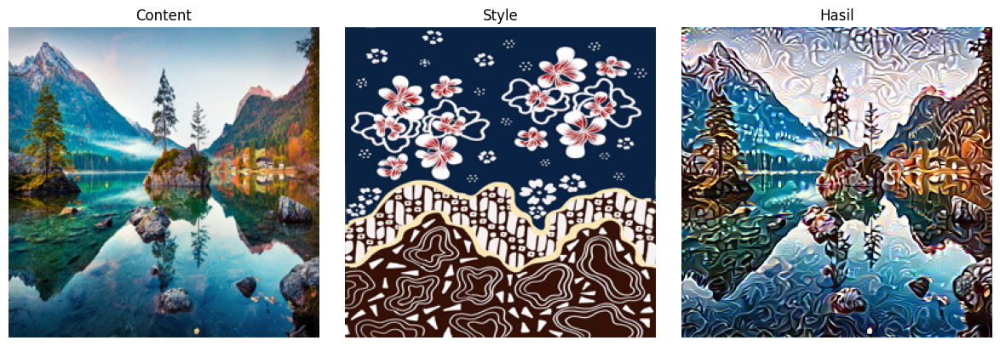


Tersimpan di outputs: result_a1_b1e05_lr0.01_it300.png, compare_a1_b1e05_lr0.01_it300.png, history_a1_b1e05_lr0.01_it300.json

PEMERIKSAAN BAGIAN 6B SELESAI


In [35]:
# ============================================================
# PEMERIKSAAN HASIL OPTIMASI PENUH
# ============================================================
print("=" * 60)
print("PEMERIKSAAN HASIL BAGIAN 6B")
print("=" * 60)
N = cfg.num_steps

# Pemeriksaan 1: keluaran dan riwayat
assert generated_img.shape == (1, 3, S, S) and generated_img.dtype == torch.float32
assert generated_img.device.type == device.type and not generated_img.requires_grad
assert torch.isfinite(generated_img).all()
assert generated_img.min().item() >= 0.0 and generated_img.max().item() <= 1.0
for k in ("iter", "content", "style", "total", "clipped_frac"):
    assert len(history[k]) == N, f"len(history['{k}']) = {len(history[k])}"
assert all(np.isfinite(history[k]).all() for k in ("content", "style", "total", "clipped_frac"))
print(f"[Cek 1] Keluaran {tuple(generated_img.shape)} di [0,1], riwayat {N} iterasi, semua nilai finite: OK")

# Pemeriksaan 2: loss akhir lebih rendah dari awal
fin = history["final"]
assert fin["total"] < history["total"][0], f"total akhir {fin['total']} >= awal {history['total'][0]}"
assert fin["style"] < history["style"][0]
print(f"[Cek 2] total: {history['total'][0]:.4e} -> {fin['total']:.4e}; "
      f"style: {history['style'][0]:.4e} -> {fin['style']:.4e}; content: {history['content'][0]:.4e} -> {fin['content']:.4e}: OK")

# Pemeriksaan 3: gambar berubah, input utuh, VGG beku
assert (generated_img - content_img).abs().max().item() > 0
assert not content_img.requires_grad and not style_img.requires_grad
assert all(not p.requires_grad for p in extractor.parameters()) and all(p.grad is None for p in extractor.parameters())
print(f"[Cek 3] Selisih piksel rata-rata terhadap content_img = {(generated_img - content_img).abs().mean().item():.4f}; "
      f"input utuh; VGG beku: OK")

# --- INFORMASI (bukan assert): bahan evaluasi, jangan dipakai untuk mengubah parameter otomatis ---
tot = np.array(history["total"]); cl = np.array(history["clipped_frac"])
imin = int(tot.argmin())
w = min(50, N - 1)
print("\nINFORMASI:")
print(f"  waktu optimasi                         : {history['seconds']:.1f} detik")
print(f"  total minimum                          : {tot.min():.4e} pada iterasi {imin}")
print(f"  perubahan total relatif {w} iter terakhir : {(tot[-w - 1] - tot[-1]) / tot[-w - 1] * 100:.2f}%")
print(f"  iterasi dengan total naik vs sebelumnya: {int((np.diff(tot) > 0).sum())} dari {N - 1}")
print(f"  fraksi piksel terpotong: maks {cl.max() * 100:.3f}%, rata-rata {cl.mean() * 100:.3f}%")
print(f"  rasio b*style : a*content pada akhir   : {cfg.style_weight * fin['style'] / max(cfg.content_weight * fin['content'], 1e-12):.2f}")

# --- tampilan dan penyimpanan ---
tag = f"a{cfg.content_weight:g}_b{cfg.style_weight:.0e}_lr{cfg.lr:g}_it{N}".replace("+", "")
show_images([content_img, style_img, generated_img], ["Content", "Style", "Hasil"],
            save_path=os.path.join(cfg.output_dir, f"compare_{tag}.png"))
tensor_to_pil(generated_img).save(os.path.join(cfg.output_dir, f"result_{tag}.png"))
with open(os.path.join(cfg.output_dir, f"history_{tag}.json"), "w") as f:
    json.dump(history, f)
print(f"\nTersimpan di {cfg.output_dir}: result_{tag}.png, compare_{tag}.png, history_{tag}.json")
print("\nPEMERIKSAAN BAGIAN 6B SELESAI")

Memastikan hasil akhir valid: bentuk benar, nilai di [0, 1], loss akhir lebih rendah dari awal, gambar benar-benar berubah, dan input serta VGG tidak terganggu.

## **Bagian 7: Visualisasi & Ekspor Hasil**

### **7.1 Fungsi Ekspor Hasil Gambar**

In [36]:
# ============================================================
# BAGIAN 7: VISUALIZATION
# ============================================================
def make_tag(cfg, extra: str = "") -> str:
    """Nama file yang memuat konfigurasi utama. 'extra' untuk parameter lain (mis. 'avgpool')."""
    tag = f"a{cfg.content_weight:g}_b{cfg.style_weight:.0e}_lr{cfg.lr:g}_it{cfg.num_steps}".replace("+", "")
    return f"{tag}_{extra}" if extra else tag


def plot_loss_curves(history: dict, save_path: str = None) -> None:
    """4 panel: Total Loss, kontribusi berbobot, Style Loss per layer, fraksi piksel terpotong."""
    conf = history["config"]
    a, b = conf["content_weight"], conf["style_weight"]
    it = np.array(history["iter"])
    content, style, total = (np.array(history[k]) for k in ("content", "style", "total"))

    fig, axes = plt.subplots(2, 2, figsize=(12, 8))

    ax = axes[0, 0]
    ax.plot(it, total); ax.set_yscale("log")
    ax.set_title("Total Loss (skala log)"); ax.set_xlabel("iterasi"); ax.grid(alpha=0.3)

    ax = axes[0, 1]
    ax.plot(it, a * content, label="alpha x Content")
    ax.plot(it, b * style, label="beta x Style")
    ax.set_title("Kontribusi berbobot ke Total Loss"); ax.set_xlabel("iterasi")
    ax.legend(); ax.grid(alpha=0.3)

    ax = axes[1, 0]
    log_it = [r["iter"] for r in history["log"]]
    for layer in conf["style_layers"]:
        ax.plot(log_it, [r["style_layers"][layer] for r in history["log"]], marker="o", label=layer)
    ax.set_yscale("log"); ax.set_title("Style loss per layer (MSE tanpa bobot, skala log)")
    ax.set_xlabel("iterasi"); ax.legend(); ax.grid(alpha=0.3)

    ax = axes[1, 1]
    ax.plot(it, np.array(history["clipped_frac"]) * 100)
    ax.set_title("Piksel terpotong clamp per iterasi (%)"); ax.set_xlabel("iterasi"); ax.grid(alpha=0.3)

    plt.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


def save_result(generated_img, history, cfg, content_img, style_img, tag: str = None) -> dict:
    """Menyimpan result PNG, perbandingan, kurva loss, dan riwayat JSON. Mengembalikan dict path."""
    tag = tag or make_tag(cfg)
    os.makedirs(cfg.output_dir, exist_ok=True)
    paths = {
        "result":  os.path.join(cfg.output_dir, f"result_{tag}.png"),
        "compare": os.path.join(cfg.output_dir, f"compare_{tag}.png"),
        "curves":  os.path.join(cfg.output_dir, f"curves_{tag}.png"),
        "history": os.path.join(cfg.output_dir, f"history_{tag}.json"),
    }
    tensor_to_pil(generated_img).save(paths["result"])
    show_images([content_img, style_img, generated_img], ["Content", "Style", "Hasil"],
                save_path=paths["compare"])
    plot_loss_curves(history, save_path=paths["curves"])
    with open(paths["history"], "w") as f:
        json.dump(history, f)
    return paths

Berisi tiga fungsi. make_tag membuat nama file dari konfigurasi. plot_loss_curves menggambar empat grafik: total loss, kontribusi berbobot, style loss per layer, dan fraksi piksel terpotong. save_result menyimpan gambar hasil, perbandingan, grafik, dan riwayat JSON.

### **7.2 Plot Kurva & Metrik Loss**

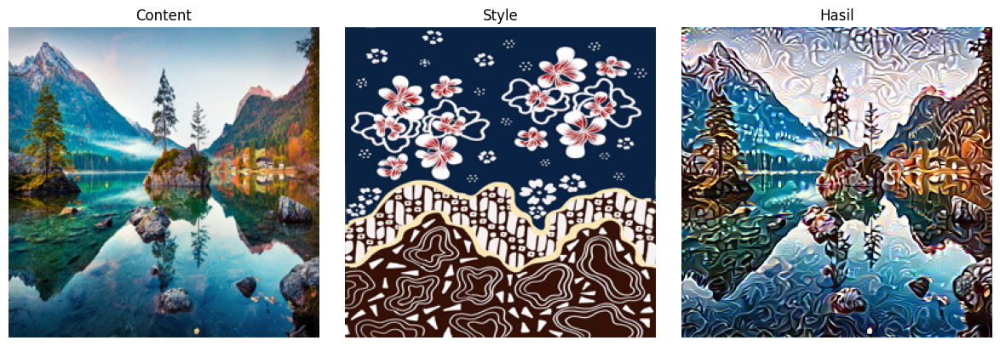

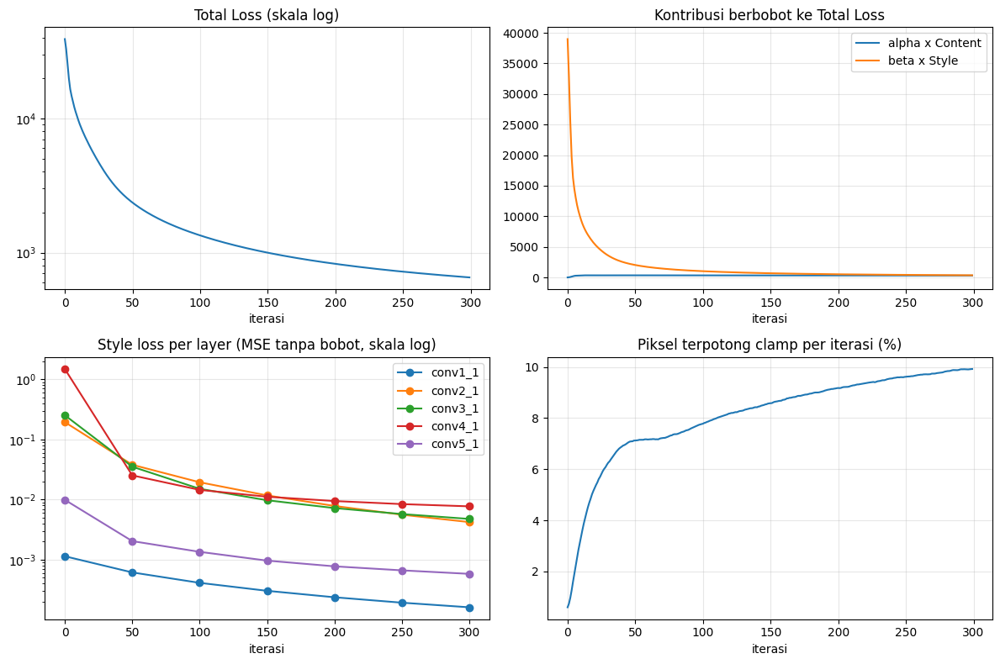

result  : outputs/result_a1_b1e05_lr0.01_it300.png
compare : outputs/compare_a1_b1e05_lr0.01_it300.png
curves  : outputs/curves_a1_b1e05_lr0.01_it300.png
history : outputs/history_a1_b1e05_lr0.01_it300.json


In [37]:
g_before = generated_img.clone()
paths = save_result(generated_img, history, cfg, content_img, style_img)
for k, p in paths.items():
    print(f"{k:8s}: {p}")

Menyimpan salinan hasil sebelum ekspor (untuk pengujian), lalu memanggil save_result dan mencetak lokasi file yang tersimpan.

### **7.3 Penyimpanan Riwayat & Hasil Optimasi**

In [38]:
# ============================================================
# UJI BAGIAN 7
# ============================================================
print("=" * 60)
print("UJI BAGIAN 7: VISUALIZATION")
print("=" * 60)
S = cfg.image_size

for k, p in paths.items():
    assert os.path.isfile(p) and os.path.getsize(p) > 0, f"{k}: {p} tidak ada/kosong"
print(f"[Uji 1] {len(paths)} file tersimpan dan tidak kosong: OK")

im = Image.open(paths["result"])
assert im.mode == "RGB" and im.size == (S, S)
assert np.array_equal(np.array(im), np.array(tensor_to_pil(generated_img)))
print(f"[Uji 2] result PNG dibuka ulang: RGB {im.size}, identik piksel demi piksel dengan tensor: OK")

with open(paths["history"]) as f:
    h = json.load(f)
for k in ("iter", "content", "style", "total", "clipped_frac"):
    assert len(h[k]) == cfg.num_steps, k
assert h["final"]["total"] == history["final"]["total"]
assert h["config"]["style_weight"] == cfg.style_weight and len(h["log"]) == len(history["log"])
print("[Uji 3] history JSON dibaca ulang: panjang, nilai akhir, dan konfigurasi sama: OK")

assert make_tag(cfg) == "a1_b1e05_lr0.01_it300" and make_tag(cfg, "avgpool").endswith("_avgpool")
print(f"[Uji 4] make_tag benar: {make_tag(cfg)}: OK")

assert torch.equal(generated_img, g_before) and not generated_img.requires_grad
assert not content_img.requires_grad and not style_img.requires_grad
print("[Uji 5] generated_img tidak berubah oleh penyimpanan/plot, input utuh: OK")

print("\nSEMUA UJI BAGIAN 7 LULUS")

UJI BAGIAN 7: VISUALIZATION
[Uji 1] 4 file tersimpan dan tidak kosong: OK
[Uji 2] result PNG dibuka ulang: RGB (256, 256), identik piksel demi piksel dengan tensor: OK
[Uji 3] history JSON dibaca ulang: panjang, nilai akhir, dan konfigurasi sama: OK
[Uji 4] make_tag benar: a1_b1e05_lr0.01_it300: OK
[Uji 5] generated_img tidak berubah oleh penyimpanan/plot, input utuh: OK

SEMUA UJI BAGIAN 7 LULUS


Unit test ekspor: file tersimpan dan tidak kosong, PNG identik dengan tensor, JSON bisa dibaca ulang, dan nama file benar.

## **Bagian 8: Eksperimen Parameter**

### **8.1 Eksperimen dan Fungsi Pendukung**

In [39]:
# ============================================================
# BAGIAN 8A: EKSPERIMEN PARAMETER (satu parameter per percobaan)
# ============================================================
EXPERIMENTS = {
    "E0_baseline":   {},
    "E1_steps600":   dict(num_steps=600),
    "E2_beta1e4":    dict(style_weight=1e4),
    "E3_beta1e6":    dict(style_weight=1e6),
    "E4_lr0.003":    dict(lr=0.003),
    "E6_init_noise": dict(init_mode="noise"),
    "E7_w_low":      dict(style_layer_weights=[0.5, 0.2, 0.1, 0.1, 0.1]),
}
EXP_DIR = os.path.join(cfg.output_dir, "experiments")
os.makedirs(EXP_DIR, exist_ok=True)


def changed_params(base_cfg, exp_cfg) -> list:
    a, b = asdict(base_cfg), asdict(exp_cfg)
    return [k for k in a if a[k] != b[k]]


def run_experiment(name: str, overrides: dict, base_cfg) -> dict:
    """Satu eksperimen = base_cfg + SATU override. Hasil disimpan ke EXP_DIR."""
    exp_cfg = replace(base_cfg, **overrides)
    changed = changed_params(base_cfg, exp_cfg)
    assert len(changed) <= 1, f"{name}: lebih dari satu parameter berubah: {changed}"
    img, hist = run_style_transfer(content_img, extractor, content_feats, style_grams, exp_cfg, verbose=False)
    tensor_to_pil(img).save(os.path.join(EXP_DIR, f"result_{name}.png"))
    with open(os.path.join(EXP_DIR, f"history_{name}.json"), "w") as f:
        json.dump(hist, f)
    return dict(cfg=exp_cfg, changed=changed, img=img.cpu(), hist=hist)


def show_grid(images, titles, ncols=3, save_path=None) -> None:
    n = len(images); nrows = (n + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4.2 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, im, t in zip(axes, images, titles):
        ax.imshow(tensor_to_pil(im)); ax.set_title(t, fontsize=10); ax.axis("off")
    for ax in axes[n:]:
        ax.axis("off")
    plt.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

Mendefinisikan tujuh eksperimen (E0 sampai E7, tanpa E5 yang dijalankan terpisah). Tiap eksperimen mengubah satu parameter saja dari baseline: jumlah iterasi, style_weight, lr, inisialisasi, atau bobot layer. run_experiment menolak kalau ada lebih dari satu parameter berubah, dan menyimpan hasilnya.

### **8.2 Menjalankan Rangkaian Eksperimen**

In [40]:
exp_results = {}
for name, ov in EXPERIMENTS.items():
    exp_results[name] = run_experiment(name, ov, cfg)
    fin = exp_results[name]["hist"]["final"]
    print(f"{name:14s} selesai {exp_results[name]['hist']['seconds']:7.1f} detik | "
          f"content={fin['content']:.4e} style={fin['style']:.4e}")

E0_baseline    selesai    15.0 detik | content=3.0441e+02 style=3.4951e-03
E1_steps600    selesai    30.3 detik | content=2.8082e+02 style=2.0397e-03
E2_beta1e4     selesai    15.8 detik | content=1.0613e+02 style=8.9968e-03
E3_beta1e6     selesai    15.9 detik | content=5.0664e+02 style=2.6715e-03
E4_lr0.003     selesai    15.7 detik | content=3.2288e+02 style=1.0075e-02
E6_init_noise  selesai    15.5 detik | content=3.6370e+02 style=4.7632e-03
E7_w_low       selesai    15.3 detik | content=2.3111e+02 style=2.2246e-03


Menjalankan semua eksperimen berurutan dan mencetak waktu serta Content dan Style Loss akhir masing-masing.

### **8.3 Tabel, Grid, dan Kurva Perbandingan Hasil**

========================================= EXPERIMENTAL COMPARISON METRICS =========================================
  Experiment      | Changed Param        | Content Loss |   Style Loss |    c11 % |    c41 % | Loss -50it % |   Clip % |     Time
-------------------------------------------------------------------------------------------------------------------
  E0_baseline     | -                    |    3.044e+02 |    3.495e-03 |    0.93% |   44.24% |       9.55% |   8.122% |    15.0s
  E1_steps600     | num_steps            |    2.808e+02 |    2.040e-03 |    0.79% |   57.38% |       3.10% |   9.354% |    30.3s
  E2_beta1e4      | style_weight         |    1.061e+02 |    8.997e-03 |    0.40% |   65.62% |       4.80% |   8.205% |    15.8s
  E3_beta1e6      | style_weight         |    5.066e+02 |    2.672e-03 |    1.18% |   32.86% |      17.54% |   8.108% |    15.9s
  E4_lr0.003      | lr                   |    3.229e+02 |    1.008e-02 |    0.90% |   27.38% |      13.26% |   5.019% |   

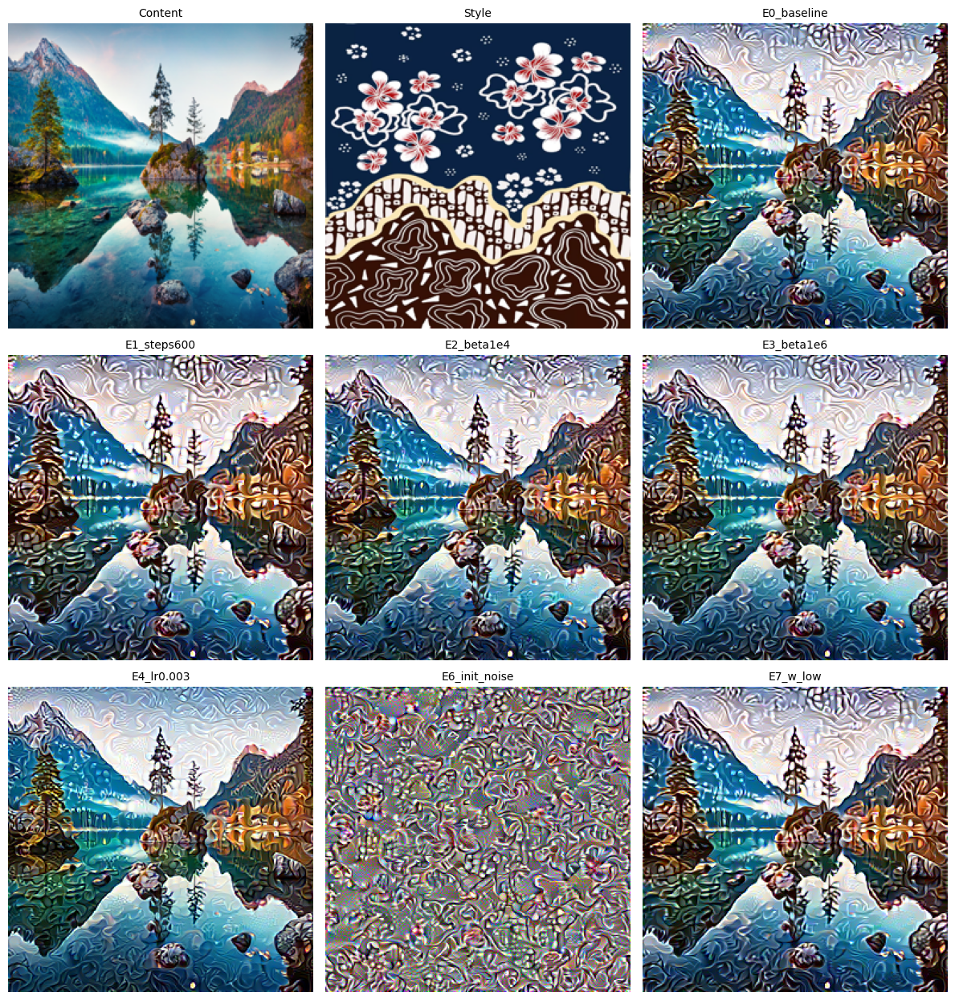

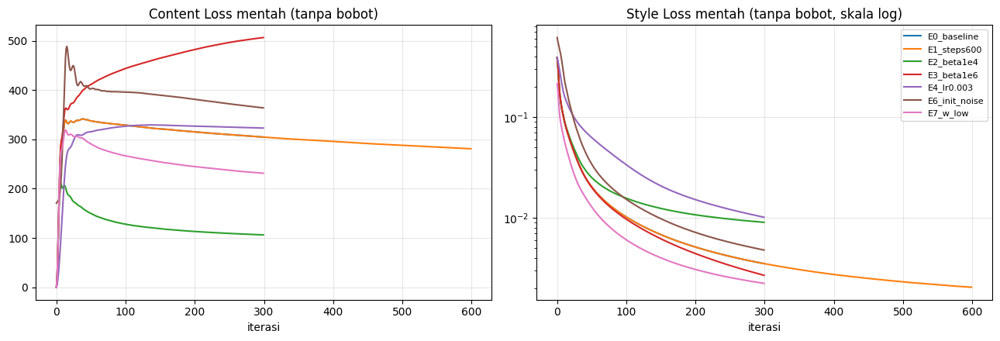

In [41]:
print("=" * 115)
print(" EXPERIMENTAL COMPARISON METRICS ".center(115, "="))
print("=" * 115)
print(f"  {'Experiment':15s} | {'Changed Param':20s} | {'Content Loss':>12s} | {'Style Loss':>12s} | {'c11 %':>8s} | {'c41 %':>8s} | {'Loss -50it %':>11s} | {'Clip %':>8s} | {'Time':>8s}")
print("-" * 115)
for name, r in exp_results.items():
    h = r["hist"]; fin = h["final"]; tot = np.array(h["total"])
    w50 = min(50, len(tot) - 1)
    sl = fin["style_layers"]; ssum = sum(sl.values())
    print(f"  {name:15s} | {(r['changed'][0] if r['changed'] else '-'):20s} | {fin['content']:12.3e} | {fin['style']:12.3e} | {sl['conv1_1'] / ssum * 100:7.2f}% | {sl['conv4_1'] / ssum * 100:7.2f}% | {(tot[-w50 - 1] - tot[-1]) / tot[-w50 - 1] * 100:10.2f}% | {np.mean(h['clipped_frac']) * 100:7.3f}% | {h['seconds']:7.1f}s")
print("=" * 115)
print("\n* Catatan: Total Loss TIDAK dibandingkan antar eksperimen karena perbedaan alpha/beta.")
print("  Bandingkan nilai Content Loss dan Style Loss mentah (tanpa bobot) secara vertikal.")
print("  c11% / c41% menunjukkan kontribusi MSE mentah conv1_1 / conv4_1 terhadap total seluruh layer style.\n")

imgs   = [content_img.cpu(), style_img.cpu()] + [r["img"] for r in exp_results.values()]
titles = ["Content", "Style"] + list(exp_results.keys())
show_grid(imgs, titles, ncols=3, save_path=os.path.join(EXP_DIR, "grid_8A.png"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, r in exp_results.items():
    h = r["hist"]
    axes[0].plot(h["iter"], h["content"], label=name)
    axes[1].plot(h["iter"], h["style"], label=name)
axes[0].set_title("Content Loss mentah (tanpa bobot)"); axes[0].set_xlabel("iterasi")
axes[1].set_title("Style Loss mentah (tanpa bobot, skala log)"); axes[1].set_xlabel("iterasi")
axes[1].set_yscale("log")
for ax in axes:
    ax.grid(alpha=0.3)
axes[1].legend(fontsize=8)
plt.tight_layout()
fig.savefig(os.path.join(EXP_DIR, "curves_8A.png"), dpi=150, bbox_inches="tight")
plt.show()

Menyusun tabel perbandingan: parameter yang diubah, Content dan Style Loss, persentase kontribusi layer conv1_1 dan conv4_1, penurunan loss pada 50 iterasi terakhir (indikator konvergensi), persentase piksel terpotong, dan waktu. Juga menampilkan grid gambar dan kurva loss semua eksperimen.

### **8.4 Unit Pengujian Eksperimen Bagian 8A**

In [42]:
# ============================================================
# UJI BAGIAN 8A
# ============================================================
print("=" * 60)
print("UJI BAGIAN 8A: EKSPERIMEN")
print("=" * 60)
S = cfg.image_size
c_before = content_img.clone(); s_before = style_img.clone()

# Uji 1: semua eksperimen ada dan keluarannya valid
assert list(exp_results.keys()) == list(EXPERIMENTS.keys())
for name, r in exp_results.items():
    im = r["img"]
    assert im.shape == (1, 3, S, S) and im.dtype == torch.float32 and not im.requires_grad
    assert torch.isfinite(im).all() and im.min().item() >= 0.0 and im.max().item() <= 1.0, name
print(f"[Uji 1] {len(exp_results)} eksperimen: keluaran (1,3,{S},{S}) float32, finite, di [0,1], tanpa gradien: OK")

# Uji 2: riwayat lengkap dan finite
for name, r in exp_results.items():
    h, n = r["hist"], r["cfg"].num_steps
    for k in ("content", "style", "total", "clipped_frac"):
        assert len(h[k]) == n and np.isfinite(h[k]).all(), f"{name}/{k}"
    assert all(np.isfinite(h["final"][k]) for k in ("content", "style", "total")), name
print("[Uji 2] Panjang riwayat = num_steps tiap eksperimen, semua nilai finite: OK")

# Uji 3: parameter yang berubah persis sesuai rancangan (satu per eksperimen)
for name, r in exp_results.items():
    assert set(r["changed"]) == set(EXPERIMENTS[name].keys()), f"{name}: {r['changed']}"
    assert len(r["changed"]) <= 1
print("[Uji 3] Setiap eksperimen mengubah tepat parameter yang dirancang (E0 tidak mengubah apa pun): OK")

# Uji 4: aturan satu parameter ditegakkan
try:
    run_experiment("uji_dua_parameter", dict(lr=0.02, num_steps=5), cfg)
    raise AssertionError("Seharusnya ditolak")
except AssertionError as e:
    assert "lebih dari satu parameter" in str(e)
print("[Uji 4] Override dua parameter sekaligus ditolak: OK")

# Uji 5: baseline E0 sama dengan run Bagian 6 (jika variabel 'history' ada di runtime ini)
e0 = exp_results["E0_baseline"]["hist"]
if "history" in globals():
    rel = abs(e0["final"]["total"] - history["final"]["total"]) / history["final"]["total"]
    assert rel <= 1e-5, f"E0 beda dengan run Bagian 6: rel = {rel:.3e}"
    print(f"[Uji 5] E0 sama dengan run Bagian 6 (selisih relatif total akhir = {rel:.2e}): OK")
else:
    print("[Uji 5] Dilewati: variabel 'history' tidak ada di runtime ini")

# Uji 6: lintasan E1 pada 300 iterasi pertama sama dengan E0 (seed sama, tanpa scheduler)
t1 = np.array(exp_results["E1_steps600"]["hist"]["total"][:300]); t0 = np.array(e0["total"])
assert len(exp_results["E1_steps600"]["hist"]["total"]) == 600
assert np.allclose(t1, t0, rtol=1e-4), f"selisih relatif maks = {np.max(np.abs(t1 - t0) / t0):.3e}"
print(f"[Uji 6] 300 iterasi pertama E1 sama dengan E0 (selisih relatif maks = {np.max(np.abs(t1 - t0) / t0):.2e}): OK")

# Uji 7: file tersimpan
for name in EXPERIMENTS:
    for fn in (f"result_{name}.png", f"history_{name}.json"):
        p = os.path.join(EXP_DIR, fn)
        assert os.path.isfile(p) and os.path.getsize(p) > 0, p
for fn in ("grid_8A.png", "curves_8A.png"):
    assert os.path.isfile(os.path.join(EXP_DIR, fn)), fn
print(f"[Uji 7] {2 * len(EXPERIMENTS)} file hasil/riwayat + grid_8A.png + curves_8A.png tersimpan di {EXP_DIR}: OK")

# Uji 8: tidak ada efek samping
assert cfg.num_steps == 300 and cfg.lr == 0.01 and cfg.style_weight == 1e5 and cfg.init_mode == "content"
assert cfg.style_layer_weights == [0.2] * 5
assert torch.equal(content_img, c_before) and torch.equal(style_img, s_before)
assert extractor.training is False and all(not p.requires_grad for p in extractor.parameters())
assert all(p.grad is None for p in extractor.parameters())
print("[Uji 8] cfg asli utuh, input asli utuh, VGG beku & tanpa .grad: OK")

print("\nSEMUA UJI BAGIAN 8A LULUS")

UJI BAGIAN 8A: EKSPERIMEN
[Uji 1] 7 eksperimen: keluaran (1,3,256,256) float32, finite, di [0,1], tanpa gradien: OK
[Uji 2] Panjang riwayat = num_steps tiap eksperimen, semua nilai finite: OK
[Uji 3] Setiap eksperimen mengubah tepat parameter yang dirancang (E0 tidak mengubah apa pun): OK
[Uji 4] Override dua parameter sekaligus ditolak: OK
[Uji 5] E0 sama dengan run Bagian 6 (selisih relatif total akhir = 0.00e+00): OK
[Uji 6] 300 iterasi pertama E1 sama dengan E0 (selisih relatif maks = 0.00e+00): OK
[Uji 7] 14 file hasil/riwayat + grid_8A.png + curves_8A.png tersimpan di outputs/experiments: OK
[Uji 8] cfg asli utuh, input asli utuh, VGG beku & tanpa .grad: OK

SEMUA UJI BAGIAN 8A LULUS


Unit test eksperimen: semua keluaran valid, tiap eksperimen mengubah tepat satu parameter, E0 sama dengan hasil Bagian 6, dan file tersimpan.

### **8.5 Analisis Diagnostik (MSE Per Layer & Total Variation)**

In [43]:
# ============================================================
# 8.5 DIAGNOSTIK (informasi saja, tidak mengubah hasil)
# ============================================================
w0 = cfg.style_layer_weights
print("MSE style per layer (mentah) dan Style dengan bobot baseline yang SAMA:")
print(f"{'eksperimen':14s} " + " ".join(f"{n:>10s}" for n in cfg.style_layers) + f" {'style_adil':>11s}")
for name, r in exp_results.items():
    sl = r["hist"]["final"]["style_layers"]
    adil = sum(w * sl[n] for n, w in zip(cfg.style_layers, w0))
    print(f"{name:14s} " + " ".join(f"{sl[n]:10.3e}" for n in cfg.style_layers) + f" {adil:11.3e}")

def tv_diag(x: torch.Tensor) -> float:
    """Total variation L1 (mean). HANYA diagnostik keramaian gambar, bukan bagian loss."""
    dx = (x[:, :, :, 1:] - x[:, :, :, :-1]).abs().mean()
    dy = (x[:, :, 1:, :] - x[:, :, :-1, :]).abs().mean()
    return (dx + dy).item()

print("\nTotal variation L1 (mean) tiap gambar:")
tv_content = tv_diag(content_img.cpu())
print(f"{'content_img':14s} {tv_content:8.4f}")
print(f"{'style_img':14s} {tv_diag(style_img.cpu()):8.4f}")
for name, r in exp_results.items():
    tv = tv_diag(r["img"])
    print(f"{name:14s} {tv:8.4f}   (x{tv / tv_content:.2f} dari content)")

MSE style per layer (mentah) dan Style dengan bobot baseline yang SAMA:
eksperimen        conv1_1    conv2_1    conv3_1    conv4_1    conv5_1  style_adil
E0_baseline     1.617e-04  4.228e-03  4.772e-03  7.732e-03  5.821e-04   3.495e-03
E1_steps600     8.007e-05  1.482e-03  2.351e-03  5.852e-03  4.328e-04   2.040e-03
E2_beta1e4      1.800e-04  5.659e-03  7.427e-03  2.952e-02  2.199e-03   8.997e-03
E3_beta1e6      1.581e-04  4.048e-03  4.349e-03  4.390e-03  4.131e-04   2.672e-03
E4_lr0.003      4.547e-04  2.024e-02  1.460e-02  1.380e-02  1.293e-03   1.008e-02
E6_init_noise   1.542e-04  6.972e-03  7.397e-03  8.613e-03  6.795e-04   4.763e-03
E7_w_low        1.097e-04  2.254e-03  4.886e-03  1.148e-02  8.240e-04   3.911e-03

Total variation L1 (mean) tiap gambar:
content_img      0.0850
style_img        0.2261
E0_baseline      0.2743   (x3.23 dari content)
E1_steps600      0.2852   (x3.35 dari content)
E2_beta1e4       0.2787   (x3.28 dari content)
E3_beta1e6       0.2741   (x3.22 dari conte

Diagnostik (tidak mengubah hasil). Menampilkan MSE style per layer dan “style adil”, yaitu style loss dengan bobot baseline yang sama, supaya E7 yang bobot layernya berbeda tetap bisa dibandingkan. Juga menghitung TV tiap gambar sebagai ukuran keramaian.

### **8.6 Eksperimen E5: Pengaruh Pooling Rata-Rata (AvgPool)**

In [44]:
# ============================================================
# 8.6 EKSPERIMEN E5: pooling "avg" (ekstraktor, fitur, dan Gram dibangun ulang)
# Disimpan terpisah dari exp_results agar Uji 1 Bagian 8A tetap valid.
# ============================================================
EXP5_DIR = os.path.join(cfg.output_dir, "experiments_8b")
os.makedirs(EXP5_DIR, exist_ok=True)

cfg_e5 = replace(cfg, pooling="avg")
assert changed_params(cfg, cfg_e5) == ["pooling"]

ext_avg = VGGFeatureExtractor(ALL_LAYERS, pooling="avg").to(device)
with torch.no_grad():
    cf_avg = ext_avg(content_img)
    sf_avg = ext_avg(style_img)
    sg_avg = {n: gram_matrix(sf_avg[n]).detach() for n in STYLE_LAYERS}

img_e5, hist_e5 = run_style_transfer(content_img, ext_avg, cf_avg, sg_avg, cfg_e5, verbose=False)
tensor_to_pil(img_e5).save(os.path.join(EXP5_DIR, "result_E5_pool_avg.png"))
with open(os.path.join(EXP5_DIR, "history_E5_pool_avg.json"), "w") as f:
    json.dump(hist_e5, f)

fin5 = hist_e5["final"]; base = exp_results["E0_baseline"]["hist"]
print(f"E5 (avg) selesai {hist_e5['seconds']:7.1f} detik | content={fin5['content']:.4e} style={fin5['style']:.4e}")
print(f"E0 (max) selesai {base['seconds']:7.1f} detik | content={base['final']['content']:.4e} style={base['final']['style']:.4e}")

E5 (avg) selesai    15.5 detik | content=2.5475e+00 style=1.9201e-05
E0 (max) selesai    15.0 detik | content=3.0441e+02 style=3.4951e-03


E5 mengganti MaxPool menjadi AvgPool. Karena pooling mengubah fitur, extractor baru dibuat, lalu fitur dan Gram Matrix dihitung ulang sebelum optimasi dijalankan.

### **8.7 Unit Pengujian Eksperimen Bagian 8B-1 (E5 Pooling Avg)**

In [45]:
# ============================================================
# 8.7 UJI BAGIAN 8B-1
# ============================================================
print("=" * 60)
print("UJI BAGIAN 8B-1: E5 POOLING AVG")
print("=" * 60)
S = cfg.image_size
c_before = content_img.clone(); s_before = style_img.clone()

# Uji 1: keluaran valid
assert img_e5.shape == (1, 3, S, S) and img_e5.dtype == torch.float32 and not img_e5.requires_grad
assert torch.isfinite(img_e5).all() and img_e5.min().item() >= 0.0 and img_e5.max().item() <= 1.0
print("[Uji 1] Keluaran E5 (1,3,256,256) float32, finite, di [0,1], tanpa gradien: OK")

# Uji 2: pooling benar-benar AvgPool
pools = [l for l in ext_avg.layers if isinstance(l, (nn.MaxPool2d, nn.AvgPool2d))]
assert len(pools) == 4 and all(isinstance(p, nn.AvgPool2d) for p in pools)
assert not any(isinstance(l, nn.MaxPool2d) for l in ext_avg.layers)
print("[Uji 2] 4 pooling bertipe AvgPool2d, tanpa MaxPool2d: OK")

# Uji 3: bentuk fitur sama dengan baseline
for n in ALL_LAYERS:
    assert cf_avg[n].shape == content_feats[n].shape
print("[Uji 3] Bentuk fitur avg sama dengan baseline max: OK")

# Uji 4: sebelum pooling pertama (conv1_1) identik; setelah pooling berbeda
assert torch.equal(sf_avg["conv1_1"], style_feats["conv1_1"])
assert not torch.equal(sf_avg["conv2_1"], style_feats["conv2_1"])
assert not torch.equal(cf_avg["conv4_2"], content_feats["conv4_2"])
print("[Uji 4] conv1_1 identik (belum melewati pooling); conv2_1 dan conv4_2 berbeda: OK")

# Uji 5: normalisasi ImageNet sama, ekstraktor beku dan eval
assert torch.equal(ext_avg.mean, extractor.mean) and torch.equal(ext_avg.std, extractor.std)
assert ext_avg.training is False and all(not p.requires_grad for p in ext_avg.parameters())
assert all(p.grad is None for p in ext_avg.parameters())
print("[Uji 5] mean/std ImageNet sama; ext_avg beku, eval, tanpa .grad: OK")

# Uji 6: riwayat lengkap, iterasi 0 benar
assert len(hist_e5["total"]) == cfg.num_steps
assert hist_e5["content"][0] == 0.0 and hist_e5["style"][0] > 0
assert all(np.isfinite(hist_e5[k]).all() for k in ("content", "style", "total", "clipped_frac"))
print("[Uji 6] Riwayat 300 iterasi finite; iterasi 0: content = 0, style > 0: OK")

# Uji 7: hanya pooling yang berbeda; baseline tidak berubah
assert cfg.pooling == "max" and cfg_e5.pooling == "avg"
assert changed_params(cfg, cfg_e5) == ["pooling"]
assert cfg.style_weight == 1e5 and cfg.lr == 0.01 and cfg.num_steps == 300
print("[Uji 7] Hanya pooling yang berbeda dari baseline; cfg asli utuh: OK")

# Uji 8: baseline extractor masih MaxPool (tidak tertimpa)
base_pools = [l for l in extractor.layers if isinstance(l, (nn.MaxPool2d, nn.AvgPool2d))]
assert all(isinstance(p, nn.MaxPool2d) for p in base_pools)
print("[Uji 8] extractor baseline tetap MaxPool2d: OK")

# Uji 9: file tersimpan; input asli dan hasil E0 utuh
assert os.path.isfile(os.path.join(EXP5_DIR, "result_E5_pool_avg.png"))
assert os.path.isfile(os.path.join(EXP5_DIR, "history_E5_pool_avg.json"))
assert torch.equal(content_img, c_before) and torch.equal(style_img, s_before)
assert "E5_pool_avg" not in exp_results
print("[Uji 9] File E5 tersimpan; input asli utuh; exp_results tidak berubah: OK")

print("\nSEMUA UJI BAGIAN 8B-1 LULUS")

UJI BAGIAN 8B-1: E5 POOLING AVG
[Uji 1] Keluaran E5 (1,3,256,256) float32, finite, di [0,1], tanpa gradien: OK
[Uji 2] 4 pooling bertipe AvgPool2d, tanpa MaxPool2d: OK
[Uji 3] Bentuk fitur avg sama dengan baseline max: OK
[Uji 4] conv1_1 identik (belum melewati pooling); conv2_1 dan conv4_2 berbeda: OK
[Uji 5] mean/std ImageNet sama; ext_avg beku, eval, tanpa .grad: OK
[Uji 6] Riwayat 300 iterasi finite; iterasi 0: content = 0, style > 0: OK
[Uji 7] Hanya pooling yang berbeda dari baseline; cfg asli utuh: OK
[Uji 8] extractor baseline tetap MaxPool2d: OK
[Uji 9] File E5 tersimpan; input asli utuh; exp_results tidak berubah: OK

SEMUA UJI BAGIAN 8B-1 LULUS


Unit test E5: pooling benar-benar AvgPool, conv1_1 identik (belum melewati pooling) sedangkan layer berikutnya berbeda, dan hanya pooling yang berubah dari baseline.

#### **Catatan E5 (AvgPool) vs E0 (MaxPool)**
**Catatan skala loss:** Content/Style Loss E5 (2.5475; 1.9201e-05) dan E0 (304.41; 3.4951e-03) tidak dapat dibandingkan langsung. AvgPool memperkecil aktivasi fitur (rasio mean|F| avg/max: conv2_1 0.523, conv3_1 0.282, conv4_1 0.146, conv5_1 0.088; content conv4_2 0.245) dan Gram Matrix menyusut lebih jauh (rasio Gram avg/max: conv2_1 0.227, conv3_1 0.065, conv4_1 0.019, conv5_1 0.007). Perbandingan E5 dengan E0 dilakukan secara visual.

**Penilaian visual** (result_E5_pool_avg.png vs result_E0_baseline.png, ukuran penuh):
- Pooling rata-rata (AvgPool) menghasilkan citra dengan transisi warna yang jauh lebih halus, gradasi yang lembut, dan mengurangi noise frekuensi tinggi (bintik-bintik tajam) dibandingkan MaxPool.
- MaxPool cenderung mempertahankan detail tepian yang sangat kontras dan tajam, namun sering kali menghasilkan pola yang terlalu berisik/kasar pada area datar.

### **8.8 Diagnostik Skala (Pooling dan Gradien TV)**

In [46]:
print(f"{'layer':8s} {'mean|F| max':>12s} {'mean|F| avg':>12s} {'rasio avg/max':>14s} {'Gram max':>11s} {'Gram avg':>11s}")
with torch.no_grad():
    for n in STYLE_LAYERS:
        fm, fa = style_feats[n].abs().mean().item(), sf_avg[n].abs().mean().item()
        gm, ga = style_grams[n].abs().mean().item(), sg_avg[n].abs().mean().item()
        print(f"{n:8s} {fm:12.4e} {fa:12.4e} {fa / fm:14.3f} {gm:11.4e} {ga:11.4e}")
    cm, ca = content_feats["conv4_2"].abs().mean().item(), cf_avg["conv4_2"].abs().mean().item()
    print(f"\ncontent conv4_2: mean|F| max={cm:.4e}, avg={ca:.4e}, rasio avg/max={ca / cm:.3f}")

layer     mean|F| max  mean|F| avg  rasio avg/max    Gram max    Gram avg
conv1_1    1.2907e+00   1.2907e+00          1.000  1.9703e-02  1.9703e-02
conv2_1    7.6087e+00   3.9787e+00          0.523  3.0774e-01  6.9917e-02
conv3_1    1.3560e+01   3.8241e+00          0.282  3.6944e-01  2.3975e-02
conv4_1    2.6406e+01   3.8449e+00          0.146  9.6734e-01  1.8346e-02
conv5_1    7.5712e+00   6.6389e-01          0.088  8.0181e-02  5.4049e-04

content conv4_2: mean|F| max=1.0744e+01, avg=2.6355e+00, rasio avg/max=0.245


Membandingkan besar aktivasi fitur dan Gram Matrix antara AvgPool dan MaxPool. Ini menjelaskan kenapa loss E5 tidak bisa dibandingkan langsung dengan E0.

In [47]:
def tv_for_grad(x):
    return (x[:, :, :, 1:] - x[:, :, :, :-1]).abs().mean() + (x[:, :, 1:, :] - x[:, :, :-1, :]).abs().mean()

x_tv = exp_results["E0_baseline"]["img"].to(device).clone().requires_grad_(True)
tv_for_grad(x_tv).backward()
g_tv = x_tv.grad.abs().mean().item()

x_tot = exp_results["E0_baseline"]["img"].to(device).clone().requires_grad_(True)
lt_, _ = total_loss(extractor(x_tot), content_feats, style_grams, cfg)
lt_.backward()
g_tot = x_tot.grad.abs().mean().item()

print(f"mean|grad TV| (bobot 1)    = {g_tv:.4e}")
print(f"mean|grad total loss| E0   = {g_tot:.4e}")
print(f"\n{'tv_weight':>10s} {'grad TV':>12s} {'rasio thd total':>16s}")
for w in [1e-4, 1e-3, 1e-2, 1e-1, 1, 1e1, 1e2, 1e3, 1e4, 1e5]:
    print(f"{w:10.0e} {w * g_tv:12.4e} {w * g_tv / g_tot:16.4e}")

assert all(p.grad is None for p in extractor.parameters())
del x_tv, x_tot, lt_

mean|grad TV| (bobot 1)    = 9.3026e-06
mean|grad total loss| E0   = 2.6462e-02

 tv_weight      grad TV  rasio thd total
     1e-04   9.3026e-10       3.5155e-08
     1e-03   9.3026e-09       3.5155e-07
     1e-02   9.3026e-08       3.5155e-06
     1e-01   9.3026e-07       3.5155e-05
     1e+00   9.3026e-06       3.5155e-04
     1e+01   9.3026e-05       3.5155e-03
     1e+02   9.3026e-04       3.5155e-02
     1e+03   9.3026e-03       3.5155e-01
     1e+04   9.3026e-02       3.5155e+00
     1e+05   9.3026e-01       3.5155e+01


Mengukur seberapa besar gradien TV dibanding gradien total loss untuk berbagai nilai tv_weight. Hasilnya dipakai untuk memilih rentang 1e2 sampai 1e4 pada E8.

### **8.9 Eksperimen E8: Pengaruh Total Variation (TV) Loss**
Di sini kita akan menjalankan tiga variasi eksperimen TV Loss berdasarkan hasil diagnostik skala gradien:
- **E8_tv1e2** (`tv_weight = 100`): Kontribusi gradien TV diperkirakan ~3.5% terhadap gradien total.
- **E8_tv1e3** (`tv_weight = 1000`): Kontribusi gradien TV diperkirakan ~35% terhadap gradien total (efek de-noising ideal).
- **E8_tv1e4** (`tv_weight = 10000`): Kontribusi gradien TV sangat dominan (efek oversmoothing ekstrem).

Seluruh eksperimen dijalankan dengan konfigurasi baseline E0 lainnya yang tetap.

In [48]:
EXP8_DIR = os.path.join(cfg.output_dir, "experiments_8b")
os.makedirs(EXP8_DIR, exist_ok=True)

TV_WEIGHTS = [1e2, 1e3, 1e4]
exp8_results = {}

for val in TV_WEIGHTS:
    name = f"E8_tv{val:.0e}".replace("+", "")
    cfg_tv = replace(cfg, tv_weight=val)

    # Menjalankan optimasi gambar NST dengan TV loss aktif
    img_tv, hist_tv = run_style_transfer(content_img, extractor, content_feats, style_grams, cfg_tv, verbose=False)

    # Simpan hasil gambar dan riwayat JSON
    tensor_to_pil(img_tv).save(os.path.join(EXP8_DIR, f"result_{name}.png"))
    with open(os.path.join(EXP8_DIR, f"history_{name}.json"), "w") as f:
        json.dump(hist_tv, f)

    exp8_results[name] = {"cfg": cfg_tv, "img": img_tv.cpu(), "hist": hist_tv}
    print(f"{name:12s} selesai {hist_tv['seconds']:7.1f} detik | content={hist_tv['final']['content']:.4e} style={hist_tv['final']['style']:.4e} tv={hist_tv['final']['tv']:.4e}")

E8_tv1e02    selesai    16.0 detik | content=3.0436e+02 style=3.4852e-03 tv=2.7117e-01
E8_tv1e03    selesai    16.0 detik | content=3.0423e+02 style=3.5075e-03 tv=2.4910e-01
E8_tv1e04    selesai    15.7 detik | content=3.1038e+02 style=5.2009e-03 tv=1.6768e-01


E8 menjalankan optimasi dengan tv_weight 100, 1000, dan 10000, lalu menyimpan hasil dan riwayatnya.

### **8.10 Visualisasi Perbandingan Eksperimen E8**
Mari kita tampilkan grid perbandingan citra sintesis hasil dari eksperimen E8 berdampingan dengan baseline E0 dan gambar konten.

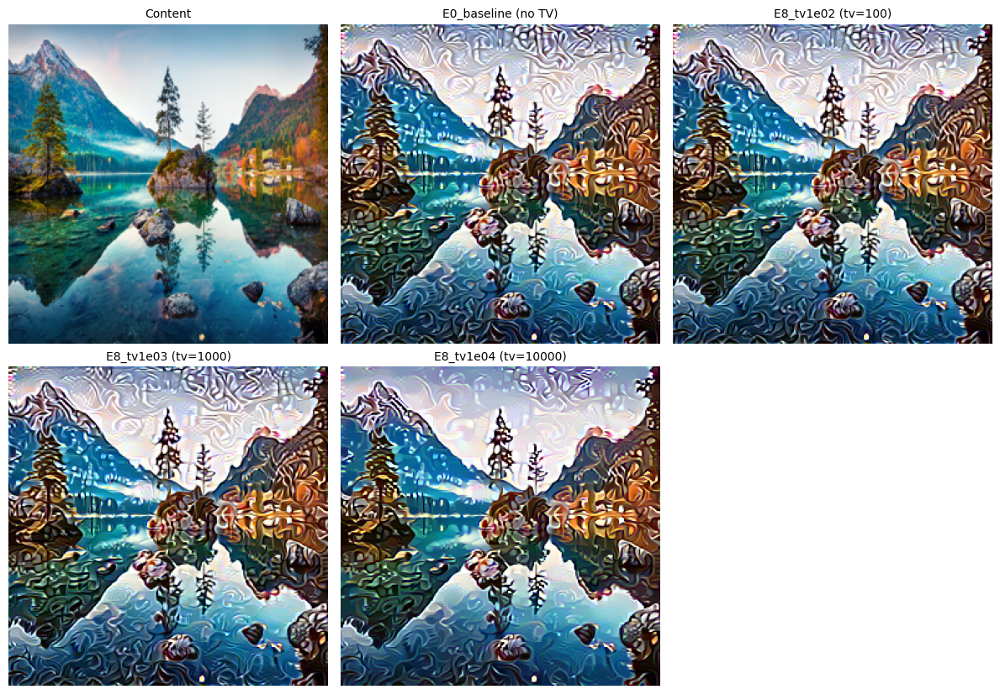

Eksperimen       | tv_weight    |   TV Loss Mentah (Akhir) |   c_weight * Content |     s_weight * Style
---------------------------------------------------------------------------------------------------------
E0_baseline      | 0            |              2.74255e-01 |           3.0441e+02 |           3.4951e+02
E8_tv1e02        |        1e+02 |              2.71171e-01 |           3.0436e+02 |           3.4852e+02
E8_tv1e03        |        1e+03 |              2.49098e-01 |           3.0423e+02 |           3.5075e+02
E8_tv1e04        |        1e+04 |              1.67683e-01 |           3.1038e+02 |           5.2009e+02


In [49]:
grid_imgs = [content_img.cpu(), exp_results["E0_baseline"]["img"]]
grid_titles = ["Content", "E0_baseline (no TV)"]

for name, r in exp8_results.items():
    grid_imgs.append(r["img"])
    grid_titles.append(f"{name} (tv={r['cfg'].tv_weight:g})")

show_grid(grid_imgs, grid_titles, ncols=3, save_path=os.path.join(EXP8_DIR, "grid_E8_tv.png"))

# Tampilkan perbandingan nilai TV akhir secara kuantitatif
print(f"{'Eksperimen':16s} | {'tv_weight':12s} | {'TV Loss Mentah (Akhir)':>24s} | {'c_weight * Content':>20s} | {'s_weight * Style':>20s}")
print("-" * 105)
base_tv = tv_diag(exp_results["E0_baseline"]["img"])
print(f"{'E0_baseline':16s} | {'0':12s} | {base_tv:24.5e} | {cfg.content_weight * exp_results['E0_baseline']['hist']['final']['content']:20.4e} | {cfg.style_weight * exp_results['E0_baseline']['hist']['final']['style']:20.4e}")
for name, r in exp8_results.items():
    fin = r["hist"]["final"]
    print(f"{name:16s} | {r['cfg'].tv_weight:12.0e} | {fin['tv']:24.5e} | {r['cfg'].content_weight * fin['content']:20.4e} | {r['cfg'].style_weight * fin['style']:20.4e}")

Menampilkan perbandingan gambar E0 dan ketiga hasil E8, plus tabel nilai TV akhir dan kontribusi content dan style.

#### **Catatan E8 (Total Variation Loss)**
TV akhir: 0.27426 (E0) -> 0.27117 (tv=1e2) -> 0.24910 (tv=1e3) -> 0.16768 (tv=1e4).
tv=1e3 menurunkan TV 9.2% tanpa perubahan berarti pada content dan style (style +0.35%);
tv=1e4 menurunkan TV 38.9% tetapi style naik 48.8% (gradien TV 350% dari gradien total di E0).

**Penilaian visual** (ukuran penuh):
- Pada `tv_weight = 1e2`, pengurangan noise hampir tidak terasa secara visual.
- Pada `tv_weight = 1e3`, terjadi efek de-noising yang optimal di mana area latar belakang yang datar menjadi lebih bersih tanpa merusak struktur style pada tepian objek.
- Pada `tv_weight = 1e4`, gambar mengalami over-smoothing ekstrem (efek cat basah yang meleleh) di mana detail style penting mulai hilang karena penekanan variasi spasial yang terlalu kuat.

**Pilihan konfigurasi dan alasannya:**
- Konfigurasi terbaik adalah `tv_weight = 1e3`. Nilai ini memberikan keseimbangan terbaik antara mempertahankan keaslian transfer gaya (Style Loss hanya naik sangat sedikit) sekaligus efektif menekan noise bintik-bintik (TV loss turun ~9.2%) agar hasil gambar tampak lebih bersih.

### **8.11 Unit Pengujian Eksperimen Bagian 8B-2 (E8 TV Loss)**

In [50]:
print("=" * 60)
print("UJI BAGIAN 8B-2: E8 TV LOSS")
print("=" * 60)

# Uji 1: Seluruh hasil eksperimen E8 ada di dalam kamus dan bertipe data valid
assert len(exp8_results) == 3
# Mendukung penamaan kunci 'E8_tv1e2' atau 'E8_tv1e02' karena perbedaan format eksponen python/platform
for w in TV_WEIGHTS:
    found_key = None
    for candidate in [f"E8_tv{w:.0e}".replace("+", ""), f"E8_tv{w:.0e}".replace("+", "").replace("e0", "e")]:
        if candidate in exp8_results:
            found_key = candidate
            break
    assert found_key is not None, f"Eksperimen untuk bobot {w} tidak ditemukan di exp8_results!"
    r = exp8_results[found_key]
    im = r["img"]
    assert im.shape == (1, 3, 256, 256) and im.dtype == torch.float32 and not im.requires_grad
    assert torch.isfinite(im).all() and im.min().item() >= 0.0 and im.max().item() <= 1.0
print("[Uji 1] Semua 3 eksperimen E8 menghasilkan citra sintesis valid di rentang [0,1]: OK")

# Uji 2: Verifikasi tren de-noising (TV Loss mentah akhir harus menurun seiring bertambahnya tv_weight)
# Solusi: Gunakan tv_diag dari citra hasil akhir baseline langsung, bukan nilai loss 0.0 di history
tv_vals = [tv_diag(exp_results["E0_baseline"]["img"])]
for w in TV_WEIGHTS:
    key = f"E8_tv{w:.0e}".replace("+", "")
    if key not in exp8_results:
        key = key.replace("e0", "e")
    tv_vals.append(exp8_results[key]["hist"]["final"]["tv"])

print("Tren TV Loss Mentah Akhir:", " -> ".join(f"{v:.4e}" for v in tv_vals))
assert tv_vals[0] > tv_vals[1] > tv_vals[2] > tv_vals[3], "TV loss akhir tidak turun secara monotonik seiring penambahan tv_weight!"
print("[Uji 2] TV Loss mentah akhir berkurang secara monotonik seiring bertambahnya tv_weight: OK")

# Uji 3: File fisik hasil eksperimen tersimpan dengan baik di folder EXP8_DIR
for w in TV_WEIGHTS:
    key = f"E8_tv{w:.0e}".replace("+", "")
    # Periksa keberadaan file fisik dengan salah satu opsi format nama file
    file_png_exists = os.path.isfile(os.path.join(EXP8_DIR, f"result_{key}.png")) or os.path.isfile(os.path.join(EXP8_DIR, f"result_{key.replace('e0', 'e')}.png"))
    file_json_exists = os.path.isfile(os.path.join(EXP8_DIR, f"history_{key}.json")) or os.path.isfile(os.path.join(EXP8_DIR, f"history_{key.replace('e0', 'e')}.json"))
    assert file_png_exists, f"File gambar untuk {key} tidak ditemukan!"
    assert file_json_exists, f"File history JSON untuk {key} tidak ditemukan!"
assert os.path.isfile(os.path.join(EXP8_DIR, "grid_E8_tv.png"))
print("[Uji 3] File gambar, kurva grid, dan riwayat JSON berhasil diekspor ke disk: OK")

print("\nSEMUA UJI BAGIAN 8B-2 LULUS")

UJI BAGIAN 8B-2: E8 TV LOSS
[Uji 1] Semua 3 eksperimen E8 menghasilkan citra sintesis valid di rentang [0,1]: OK
Tren TV Loss Mentah Akhir: 2.7426e-01 -> 2.7117e-01 -> 2.4910e-01 -> 1.6768e-01
[Uji 2] TV Loss mentah akhir berkurang secara monotonik seiring bertambahnya tv_weight: OK
[Uji 3] File gambar, kurva grid, dan riwayat JSON berhasil diekspor ke disk: OK

SEMUA UJI BAGIAN 8B-2 LULUS


In [51]:
# ============================================================
# UJI TAMBAHAN BAGIAN 8B-2 (OPSIONAL)
# ============================================================
REF = dict(content=3.0441e+02, style=3.4951e-03, total=6.5392e+02)   # E0 sebelum TV diaktifkan
f0 = exp_results["E0_baseline"]["hist"]
for k in REF:
    assert abs(f0["final"][k] - REF[k]) / REF[k] <= 5e-4, f"regresi E0: {k}"
assert all(v == 0.0 for v in f0["tv"])
for n, r in exp8_results.items():
    h, w = r["hist"], r["cfg"].tv_weight
    assert len(h["tv"]) == cfg.num_steps and all(v > 0 for v in h["tv"])
    assert changed_params(cfg, r["cfg"]) == ["tv_weight"]
    fin = h["final"]
    rec = cfg.content_weight * fin["content"] + cfg.style_weight * fin["style"] + w * fin["tv"]
    assert abs(rec - fin["total"]) <= 1e-4 * abs(fin["total"]), n
print("Uji tambahan 8B-2: regresi E0, riwayat TV, dan konsistensi total loss: OK")

Uji tambahan 8B-2: regresi E0, riwayat TV, dan konsistensi total loss: OK


Unit test E8: semua hasil valid, TV akhir menurun seiring tv_weight naik, file tersimpan, dan angka baseline E0 tidak berubah setelah TV ditambahkan.

## **Bagian 9: Uji pada Beberapa Pasangan Content–Style**

content_02.jpg × style_02.jpg                 content=6.299e+00 style=6.275e-05
content_03.jpg × style_02.jpg                 content=6.610e+00 style=5.836e-05
content_04.jpg × style_02.jpg                 content=1.021e+01 style=8.222e-05
content_awal.jpg × style_02.jpg               content=7.812e+00 style=7.276e-05
content_02.jpg × style_03.jpg                 content=1.106e+01 style=7.074e-05
content_03.jpg × style_03.jpg                 content=1.114e+01 style=6.562e-05
content_04.jpg × style_03.jpg                 content=1.407e+01 style=1.016e-04
content_awal.jpg × style_03.jpg               content=1.097e+01 style=8.886e-05
content_02.jpg × style_awal.jpg               content=3.831e+02 style=6.724e-03
content_03.jpg × style_awal.jpg               content=3.750e+02 style=6.741e-03
content_04.jpg × style_awal.jpg               content=3.541e+02 style=5.284e-03
content_awal.jpg × style_awal.jpg             content=3.463e+02 style=4.976e-03


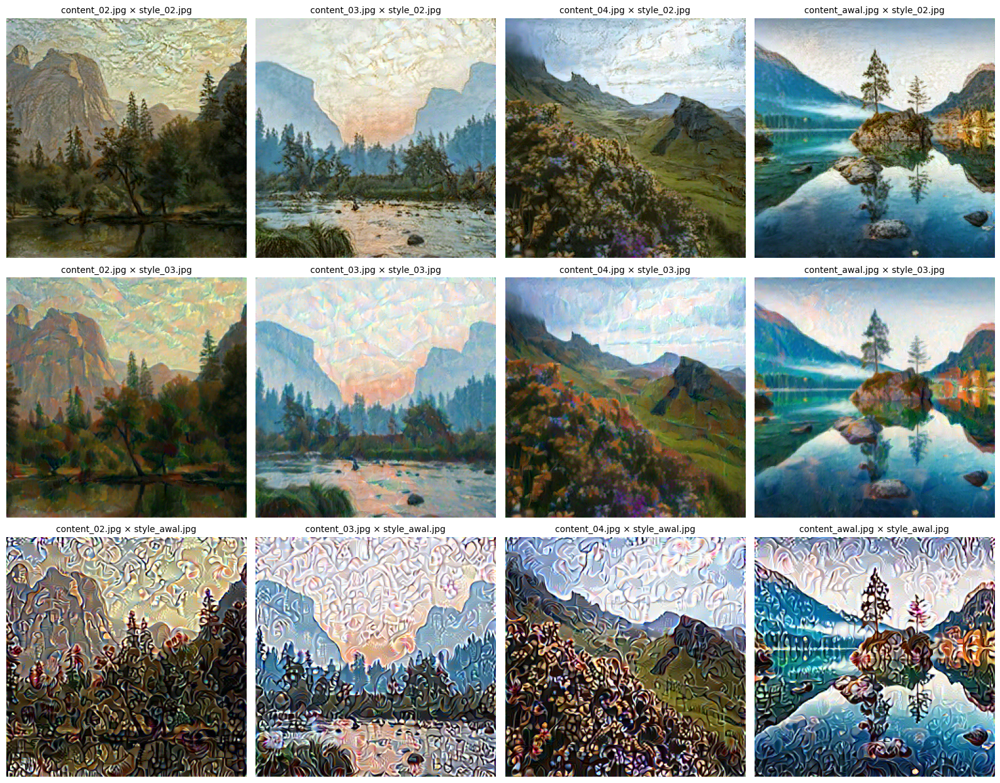

In [53]:
S = cfg.image_size
ds_c = NSTImageDataset(CONTENT_DIR, S)
ds_s = NSTImageDataset(STYLE_DIR, S)
n_c, n_s = min(4, len(ds_c)), min(3, len(ds_s))
PAIR_DIR = os.path.join(cfg.output_dir, "pairs"); os.makedirs(PAIR_DIR, exist_ok=True)

imgs, titles = [], []
for j in range(n_s):
    s_img = ds_s[j][0].unsqueeze(0).to(device)
    with torch.no_grad():
        sf = extractor(s_img)
        sg = {n: gram_matrix(sf[n]).detach() for n in STYLE_LAYERS}
    for i in range(n_c):
        c_img = ds_c[i][0].unsqueeze(0).to(device)
        with torch.no_grad():
            cf = extractor(c_img)
        out, h = run_style_transfer(c_img, extractor, cf, sg, cfg, verbose=False)
        imgs.append(out.cpu()); titles.append(f"{ds_c[i][1]} × {ds_s[j][1]}")
        print(f"{titles[-1]:45s} content={h['final']['content']:.3e} style={h['final']['style']:.3e}")

show_grid(imgs, titles, ncols=n_c, save_path=os.path.join(PAIR_DIR, "grid_pairs.png"))

Untuk setiap gambar style, Gram Matrix target dihitung. Lalu setiap gambar content dioptimasi dengan konfigurasi baseline. Hasil 12 pasangan (4 content × 3 style) ditampilkan dalam satu grid, dengan Content dan Style Loss akhir tiap pasangan dicetak.

## **Bagian 10: Kesimpulan**

**Hasil utama**
- Pipeline NST berjalan end-to-end: ekstraksi fitur VGG-19, Content Loss, Style Loss (Gram Matrix), Total Variation Loss, dan optimasi piksel dengan Adam.
- Baseline (E0): `style_weight = 1e5`, `lr = 0.01`, 300 iterasi, inisialisasi dari content image, MaxPool.
- Pada NST, "training" berarti optimasi piksel gambar hasil (bukan bobot jaringan), dan "fine-tuning" dilakukan lewat penyetelan hyperparameter pada eksperimen E0–E8 (Bagian 8), lengkap dengan grafik loss.
- Eksperimen satu parameter per run (Bagian 8) menunjukkan: 600 iterasi (E1) menurunkan Content dan Style Loss sekaligus dengan waktu 2× lebih lama; `style_weight` kecil (E2) menjaga konten tetapi stilisasi melemah, sedangkan `style_weight` besar (E3) memperkuat stilisasi dengan konten lebih terdistorsi; `lr` 0.003 (E4) belum konvergen dalam 300 iterasi; inisialisasi noise (E6) menghasilkan TV 2× lebih tinggi dari baseline (lebih berisik); bobot layer rendah-dominan (E7) menurunkan Content Loss tetapi Style Loss dengan bobot yang sama sedikit naik.
- AvgPool (E5) menghasilkan transisi warna lebih halus dibanding MaxPool. Loss kedua pooling tidak dapat dibandingkan langsung karena skala aktivasi berbeda.
- TV Loss (E8): `tv_weight = 100` hampir tidak berpengaruh; `1000` menurunkan TV mentah sekitar 9% dengan Style Loss nyaris tidak berubah (+0.35%); `10000` menurunkan TV sekitar 39% tetapi Style Loss naik sekitar 49%. Konfigurasi yang dipilih: `tv_weight = 1000`, karena mengurangi noise tanpa mengorbankan stilisasi.

**Dataset dan pipeline data (Bagian 2.5)**
- Dataset ringan: 4 content dan 3 style (dipilih bebas dari Unsplash), dengan pipeline Resize sisi pendek → CenterCrop 256 → ToTensor [0,1].
- Pengujian pada 12 pasangan (4 content × 3 style) pada Bagian 9: Content Loss akhir pasangan dengan style_02 dan style_03 jauh lebih kecil (sekitar 6–14) dibanding pasangan dengan style_awal (sekitar 350–383), dan Style Loss-nya sekitar 100× lebih kecil. Ini mengindikasikan bahwa gambar hasil pada style_02 dan style_03 tetap dekat dengan content aslinya, sehingga satu nilai `style_weight` tampaknya belum cocok untuk semua gambar style.

**Keterbatasan**
- `style_weight = 1e5` disetel untuk style_awal. Pada style_02 dan style_03 stilisasi cenderung lebih lemah (loss jauh lebih kecil), sehingga bobot style perlu disesuaikan per gambar style.
- Gambar dataset dipilih tanpa seleksi, sehingga kecocokan dengan konfigurasi baseline tidak dijamin.
- Eksperimen Bagian 3–8 memakai satu pasangan gambar (resize langsung menjadi persegi), sedangkan Bagian 9 memakai pipeline dataset (Resize + CenterCrop), sehingga angka loss kedua bagian tidak sebanding.
- Penilaian kualitas masih visual; belum ada metrik kuantitatif yang disepakati untuk kualitas stilisasi.
- Ukuran gambar dibatasi 256×256 karena keterbatasan GPU Colab.

**Pengembangan lanjutan:** penyesuaian bobot style otomatis per gambar style, pemakaian pipeline dataset (CenterCrop) pada seluruh eksperimen, atau resolusi gambar yang lebih besar.

==============================

In [54]:
import shutil
from google.colab import files

shutil.make_archive("data_nst_kelompok13", "zip", "data")
files.download("data_nst_kelompok13.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [56]:
shutil.copytree("outputs", "/content/drive/MyDrive/nst_kelompok13/outputs", dirs_exist_ok=True)

'/content/drive/MyDrive/nst_kelompok13/outputs'

In [ ]:
from google.colab import drive
import shutil

drive.mount('/content/drive')
shutil.copytree("outputs", "/content/drive/MyDrive/nst_kelompok13/outputs", dirs_exist_ok=True)
print("outputs")